# CNN Practical Assignment (PyTorch): Brain Tumor MRI Classification
**Deep Learning for Image Analysis · Department of Electrical Engineering · National Taipei University**

| Item | Details |
|---|---|
| Dataset | **Brain Tumor Classification (MRI)**, Sartaj Bhuvaji *et al.* (2020) |
| Download / source link | https://github.com/sartajbhuvaji/brain-tumor-classification-dataset (also on Kaggle: https://www.kaggle.com/datasets/sartajbhuvaji/brain-tumor-classification-mri) |
| Classes (4) | glioma tumor · meningioma tumor · no tumor · pituitary tumor |
| Framework | PyTorch + torchvision, OpenCV (preprocessing), scikit-learn (split and metrics) |

### Where each assignment task is answered
| Task | Section |
|---|---|
| 1. Download images, show samples per class | §1 |
| 2. Resize / normalize, train-validation-test split, set sizes | §2 |
| 3. CNN in PyTorch (conv, ReLU, pooling, flatten, FC), architecture and parameter count | §3 |
| 4. Visualize every layer (input, conv, activation, pooling, output shapes) | §4 (initial weights) and §5.1 (trained weights) |
| 5. Train, accuracy/loss per epoch, learning curves | §5 |
| 6. Test: accuracy, precision, recall, F1, confusion matrix, correct and incorrect examples | §6 |
| 7. With vs. without preprocessing, two CNN configurations, tables and figures | §7 |
| 8. Purpose of each layer, symbols, equations, abbreviations, observations | §8 and the *Observation* boxes after every experiment |

**How to run.** Run all cells top to bottom (Colab: *Runtime → Run all*; a GPU is optional). The dataset is cloned from GitHub automatically. All experiments use the **same seed (42)** and the **same train/validation/test split** (saved to `split.csv`). All figures are also saved to `figures/`.

> The saved outputs were produced on a 2-core CPU. On a GPU the numbers can differ slightly because of non-deterministic GPU kernels.

## 0 · Setup
Libraries, random seeds (for reproducibility) and the global settings used by **every** experiment.

In [1]:
import os, time, random, hashlib, copy, json, subprocess, warnings
from collections import OrderedDict
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision.transforms import v2 as T
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
from IPython.display import display
warnings.filterwarnings("ignore")

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---- global settings (identical for all experiments) ----
IMG_SIZE     = 128      # every image is resized to 128 x 128 pixels
BATCH_SIZE   = 32
MAX_EPOCHS   = 60       # upper limit; early stopping decides the actual number of epochs
PATIENCE     = 8        # early stopping: stop after 8 epochs without a lower validation loss
LR           = 1e-3     # Adam learning rate
WEIGHT_DECAY = 1e-4     # L2 penalty

DATA_DIR = "brain-tumor-classification-dataset"
FIG_DIR  = "figures"; os.makedirs(FIG_DIR, exist_ok=True)
CLASSES  = ["glioma_tumor", "meningioma_tumor", "no_tumor", "pituitary_tumor"]
NAMES    = ["glioma", "meningioma", "no tumor", "pituitary"]          # short names for plots
COLORS   = ["#2457D6", "#B7600A", "#0E7C6B", "#8E3BB5"]

def savefig(name):
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(f"PyTorch {torch.__version__} | torchvision {torchvision.__version__} | OpenCV {cv2.__version__}")
print(f"Device: {DEVICE} | CPU threads: {torch.get_num_threads()}")

PyTorch 2.15.0+cu132 | torchvision 0.29.2+cu132 | OpenCV 5.0.0
Device: cpu | CPU threads: 2


## 1 · Download the images (Task 1)
**Dataset:** *Brain Tumor Classification (MRI)*, 3,264 brain MRI slices (JPEG) in four classes, shipped in two folders (`Training`, `Testing`).
**Source:** https://github.com/sartajbhuvaji/brain-tumor-classification-dataset

The cell below clones the repository (about 90 MB) if it is not already present, lists every file, and computes an MD5 hash of each file so that **exact duplicate images can be removed** before splitting. Otherwise the same picture could land in both the training and the test set, which would make the test score too optimistic (*data leakage*).

In [2]:
REPO = "https://github.com/sartajbhuvaji/brain-tumor-classification-dataset.git"
if not os.path.isdir(DATA_DIR):
    subprocess.run(["git", "clone", "--depth", "1", REPO, DATA_DIR], check=True)

rows = []
for folder in ["Training", "Testing"]:
    for label, cls in enumerate(CLASSES):
        d = os.path.join(DATA_DIR, folder, cls)
        for fn in sorted(os.listdir(d)):
            path = os.path.join(d, fn)
            with open(path, "rb") as f:
                md5 = hashlib.md5(f.read()).hexdigest()
            rows.append(dict(path=path, cls=cls, label=label, folder=folder, md5=md5))
df_all = pd.DataFrame(rows)
print("Files as downloaded (original folders):")
display(pd.crosstab(df_all.cls, df_all.folder, margins=True, margins_name="total"))

Files as downloaded (original folders):

folder,Testing,Training,total
cls,,,
glioma_tumor,100,826,926
meningioma_tumor,115,822,937
no_tumor,105,395,500
pituitary_tumor,74,827,901
total,394,2870,3264


In [3]:
# Remove exact duplicates: identical files with different labels are dropped completely,
# identical files with the same label are kept once.
labels_per_hash = df_all.groupby("md5").label.nunique()
conflicts = labels_per_hash[labels_per_hash > 1].index
n_conflict_files = int(df_all.md5.isin(conflicts).sum())
df = (df_all[~df_all.md5.isin(conflicts)]
      .drop_duplicates("md5").reset_index(drop=True))
n_dupes = len(df_all) - n_conflict_files - len(df)

sizes = np.array([cv2.imread(p, cv2.IMREAD_GRAYSCALE).shape for p in df.path])
df["height"], df["width"] = sizes[:, 0], sizes[:, 1]

print(f"downloaded files                : {len(df_all)}")
print(f"duplicate copies removed        : {n_dupes}")
print(f"conflicting-label files removed : {n_conflict_files}")
print(f"unique images kept              : {len(df)}")
print("\nUnique images per class:"); display(df.cls.value_counts().reindex(CLASSES).to_frame("images"))
print("Most common original sizes (H x W):")
display(df.groupby(["height", "width"]).size().sort_values(ascending=False).head(6).to_frame("images"))

downloaded files                : 3264
duplicate copies removed        : 237
conflicting-label files removed : 0
unique images kept              : 3027

Unique images per class:


,images
cls,
glioma_tumor,902
meningioma_tumor,927
no_tumor,352
pituitary_tumor,846


Most common original sizes (H x W):


,,images
height,width,
512,512,2302
236,236,44
225,225,37
442,442,20
256,256,17
350,350,9


In [4]:
# Data audit: (1) duplicates shared by the ORIGINAL Training and Testing folders,
#             (2) where the images of each class come from (image size is a proxy for the source)
folders_per_hash = df_all.groupby("md5").folder.nunique()
print(f"images with copies in BOTH original folders (Training and Testing): {(folders_per_hash > 1).sum()}")
audit = df.groupby("cls").apply(lambda g: pd.Series({
    "images": len(g), "% 512x512": 100 * ((g.height == 512) & (g.width == 512)).mean(),
    "distinct sizes": g.groupby(["height", "width"]).ngroups}), include_groups=False)
display(audit.astype({"images": int, "distinct sizes": int}).round(1))

images with copies in BOTH original folders (Training and Testing): 64


,images,% 512x512,distinct sizes
cls,,,
glioma_tumor,902,92.5,64
meningioma_tumor,927,72.9,129
no_tumor,352,1.1,231
pituitary_tumor,846,93.1,32


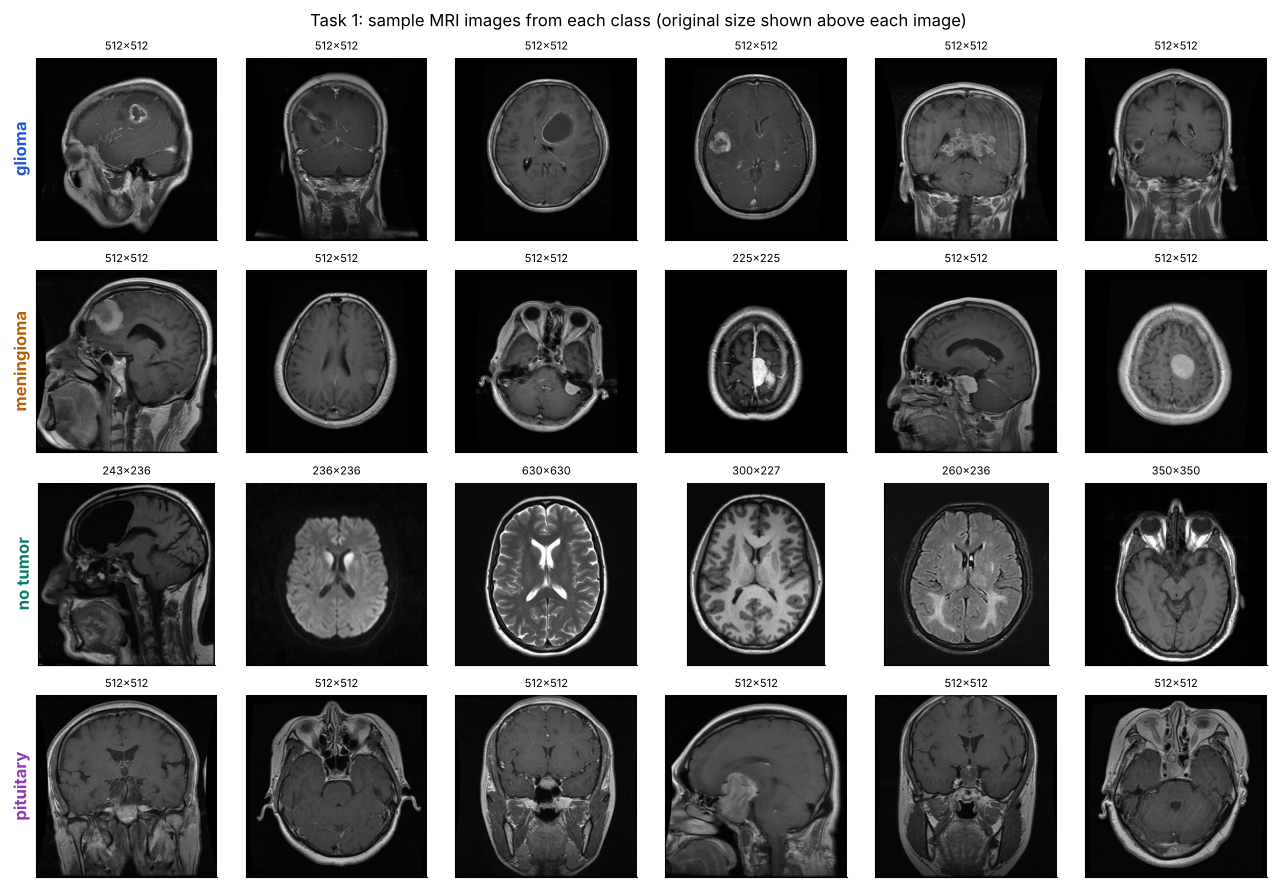

In [5]:
# Sample images from every class (original resolution, before any preprocessing)
rng = np.random.RandomState(SEED)
n_show = 6
fig, axes = plt.subplots(4, n_show, figsize=(13, 9))
for r, cls in enumerate(CLASSES):
    paths = df[df.cls == cls].path.values
    for c, p in enumerate(rng.choice(paths, n_show, replace=False)):
        img = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
        axes[r, c].imshow(img, cmap="gray"); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        axes[r, c].set_title(f"{img.shape[0]}×{img.shape[1]}", fontsize=8)
    axes[r, 0].set_ylabel(NAMES[r], fontsize=12, fontweight="bold", color=COLORS[r])
fig.suptitle("Task 1: sample MRI images from each class (original size shown above each image)", fontsize=12)
plt.tight_layout(); savefig("01_samples"); plt.show()

**Observation (Task 1)**
* 3,264 files were downloaded but only **3,027 are unique**: 237 files are exact copies, and **64 images appear in both of the original `Training` and `Testing` folders**. Using the original folders as the train/test split would test the model partly on images it has already trained on. That is why duplicates are removed here and the data are re-split in §2.
* The classes are **imbalanced**: *no tumor* has 352 images, the other classes 846–927. Besides accuracy we therefore report **macro-averaged** precision, recall and F1, where every class counts equally.
* The classes come from **different sources**: 92–93 % of the glioma and pituitary images are 512×512, but only 1.1 % (4 of 352) of the *no tumor* images, which come in 231 different sizes and include other MRI contrasts (e.g. bright ventricles, typical of T2-weighted scans, in the samples above). A CNN could partly learn *which source an image comes from* instead of *whether there is a tumor*, a shortcut that resizing alone does not remove. This is kept in mind when reading the results.
* Axial, coronal and sagittal slices are mixed in every class, so the network has to recognise each tumor type from several viewing directions.

## 2 · Prepare the dataset (Task 2)
### 2.1 Train / validation / test split
The unique images are split **once**, stratified by class (each split keeps the class proportions): **70 % training, 15 % validation, 15 % test**.
* **Training set**: updates the weights.
* **Validation set**: chooses the best epoch (early stopping) and compares settings.
* **Test set**: used only at the end, to report the final, unbiased score.

The split is saved to `split.csv` and reused by **every** experiment in §7, so comparisons are fair.

Number of images in each set:


split,train,val,test,total
cls,,,,
glioma_tumor,631,135,136,902
meningioma_tumor,649,139,139,927
no_tumor,246,53,53,352
pituitary_tumor,592,127,127,846
total,2118,454,455,3027


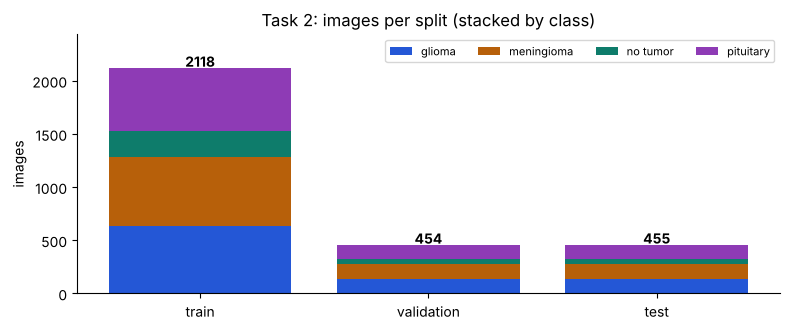

In [6]:
idx = np.arange(len(df))
train_idx, temp_idx = train_test_split(idx, test_size=0.30, stratify=df.label, random_state=SEED)
val_idx, test_idx   = train_test_split(temp_idx, test_size=0.50, stratify=df.label.iloc[temp_idx], random_state=SEED)
SPLITS = {"train": np.sort(train_idx), "val": np.sort(val_idx), "test": np.sort(test_idx)}
df["split"] = ""
for s, ix in SPLITS.items(): df.loc[ix, "split"] = s
df[["path", "cls", "label", "split", "md5"]].to_csv("split.csv", index=False)

assert not (set(df.md5[SPLITS["train"]]) & set(df.md5[SPLITS["test"]])), "leakage!"
counts = pd.crosstab(df.cls, df.split)[["train", "val", "test"]]
counts.loc["total"] = counts.sum()
counts["total"] = counts.sum(axis=1)
print("Number of images in each set:"); display(counts)

fig, ax = plt.subplots(figsize=(8, 3.4))
bottom = np.zeros(3)
for k, cls in enumerate(CLASSES):
    v = counts.loc[cls, ["train", "val", "test"]].values
    ax.bar(["train", "validation", "test"], v, bottom=bottom, color=COLORS[k], label=NAMES[k]); bottom += v
for i, t in enumerate(bottom): ax.text(i, t + 15, f"{int(t)}", ha="center", fontweight="bold")
ax.set_ylabel("images"); ax.set_title("Task 2: images per split (stacked by class)"); ax.legend(ncol=4, fontsize=8, loc="upper right")
ax.set_ylim(0, bottom.max() * 1.15)
plt.tight_layout(); savefig("02_split_counts"); plt.show()

### 2.2 Two preprocessing pipelines
Both pipelines start the same way: read the JPEG as **grayscale** (the MRI slices carry no colour information, so 1 channel instead of 3) and **resize to 128 × 128** (`cv2.INTER_AREA`, the usual choice for shrinking). The original images have many different sizes, so resizing is required before they can be stacked into a batch.

| Pipeline | Steps | Used for |
|---|---|---|
| **Basic** | resize → tensor in [0, 1] (`/255`) | baseline in §7 |
| **Enhanced** | resize → **median filter 3×3** (noise reduction) → **CLAHE** (contrast enhancement) → tensor in [0, 1] → **z-score normalization** with the training-set mean and std → **augmentation** (training images only: random horizontal flip, rotation ±10°, shift ±5 %, scale 0.95–1.05) | main model (§5–6) and §7 |

The deterministic steps (resize, median, CLAHE) are computed once and cached in memory. Augmentation is random, so it is applied on the fly in every epoch.

In [7]:
CLAHE = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def load_gray(path):      return cv2.imread(path, cv2.IMREAD_GRAYSCALE)
def resize(img):          return cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
def denoise(img):         return cv2.medianBlur(img, 3)          # noise reduction
def contrast(img):        return CLAHE.apply(img)                 # contrast enhancement
def enhance(img):         return contrast(denoise(img))

t0 = time.time()
X_basic = np.stack([resize(load_gray(p)) for p in df.path])      # (N, 128, 128) uint8
X_enh   = np.stack([enhance(x) for x in X_basic])
y_all   = df.label.values.astype(np.int64)

# normalization statistics from the TRAINING images only (no information from val/test)
MEAN = float((X_enh[SPLITS["train"]] / 255.0).mean())
STD  = float((X_enh[SPLITS["train"]] / 255.0).std())
print(f"cached {len(X_basic)} images of {X_basic.shape[1:]} in {time.time() - t0:.1f}s")
print(f"Enhanced pipeline normalization: mean = {MEAN:.4f}, std = {STD:.4f} (training set)")

cached 3027 images of (128, 128) in 2.8s
Enhanced pipeline normalization: mean = 0.2885, std = 0.2622 (training set)


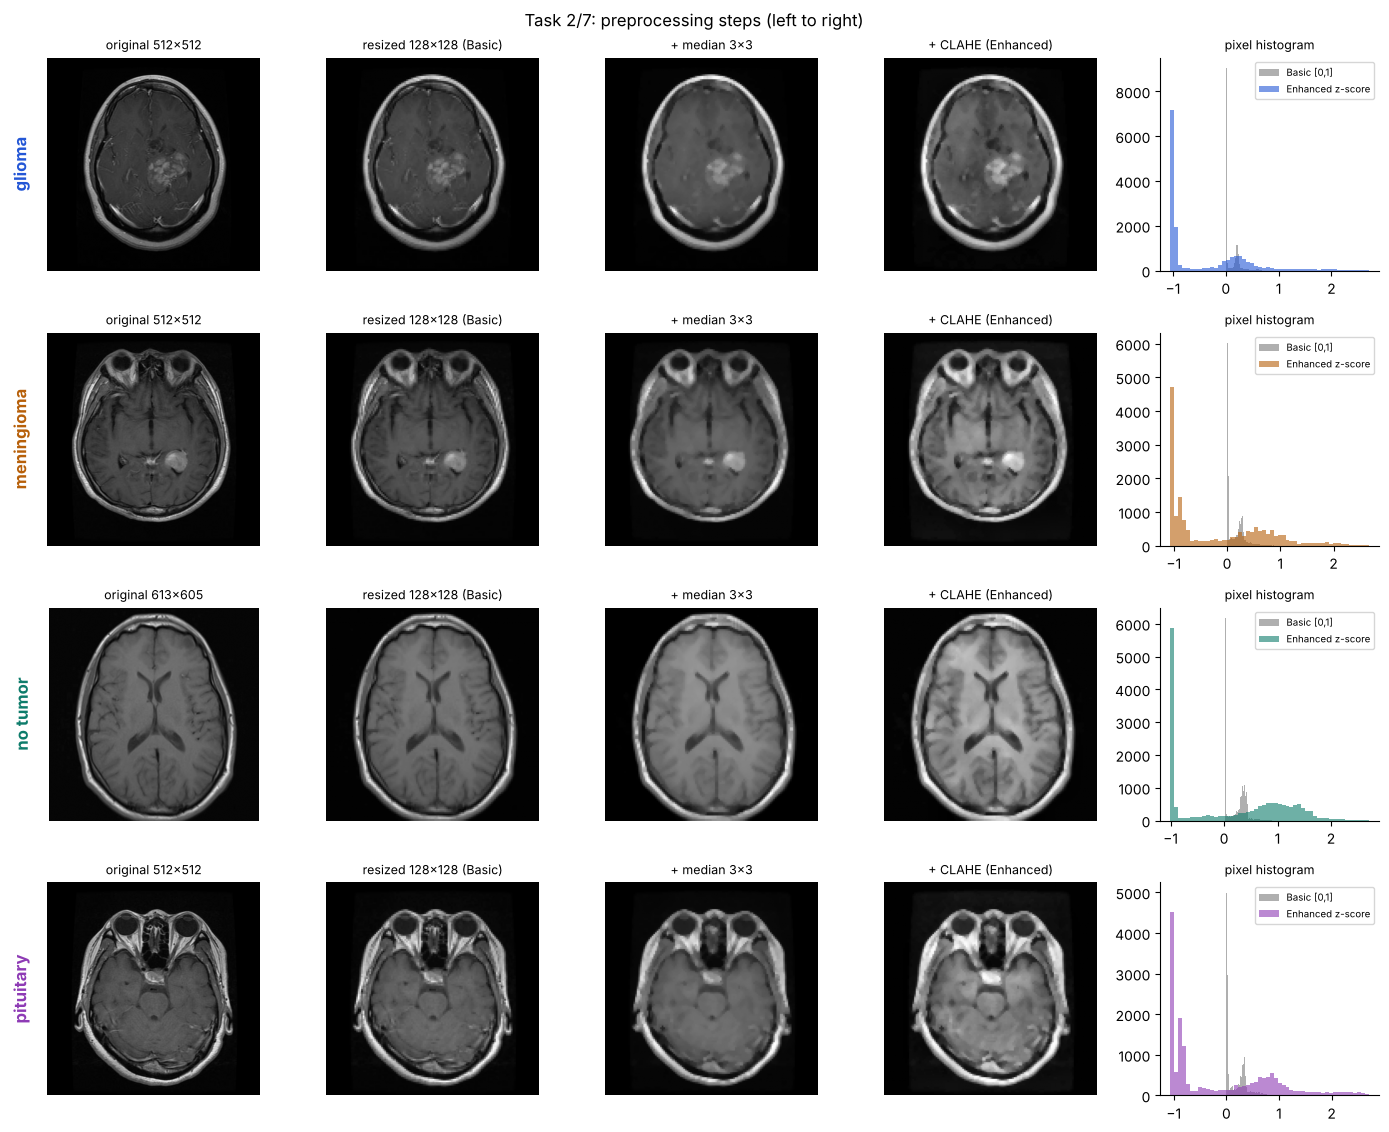

In [8]:
# Visual check: the preprocessing steps on one image of each class
ex = [int(df.index[(df.split == "train") & (df.label == k)][0]) for k in range(4)]
fig, axes = plt.subplots(4, 5, figsize=(14, 11.5))
for r, i in enumerate(ex):
    orig = load_gray(df.path[i]); small = X_basic[i]; den = denoise(small); cl = contrast(den)
    norm = (cl / 255.0 - MEAN) / STD
    for c, (img, t) in enumerate([(orig, f"original {orig.shape[0]}×{orig.shape[1]}"), (small, "resized 128×128 (Basic)"),
                                  (den, "+ median 3×3"), (cl, "+ CLAHE (Enhanced)")]):
        axes[r, c].imshow(img, cmap="gray"); axes[r, c].set_title(t, fontsize=9); axes[r, c].axis("off")
    axes[r, 4].hist((small / 255.0).ravel(), bins=50, alpha=.6, label="Basic [0,1]", color="#7A7A7A")
    axes[r, 4].hist(norm.ravel(), bins=50, alpha=.6, label="Enhanced z-score", color=COLORS[r])
    axes[r, 4].set_title("pixel histogram", fontsize=9); axes[r, 4].legend(fontsize=7)
    axes[r, 0].text(-0.08, 0.5, NAMES[r], transform=axes[r, 0].transAxes, rotation=90, va="center", ha="right",
                    fontsize=12, fontweight="bold", color=COLORS[r])
fig.suptitle("Task 2/7: preprocessing steps (left to right)", fontsize=12)
plt.tight_layout(); savefig("02_preprocessing_steps"); plt.show()

In [9]:
class MRIDataset(Dataset):
    # images: uint8 array (N, H, W); returns a normalized float tensor (1, H, W) and the label
    def __init__(self, images, labels, mean=0.0, std=1.0, augment=None):
        self.x = torch.from_numpy(images).float().div(255.0).unsqueeze(1)   # tensor conversion, [0, 1]
        self.y = torch.from_numpy(labels)
        self.mean, self.std, self.augment = mean, std, augment
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        x = self.x[i]
        if self.augment is not None: x = self.augment(x)
        return (x - self.mean) / self.std, self.y[i]

AUGMENT = T.Compose([T.RandomHorizontalFlip(p=0.5),
                     T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.95, 1.05))])

PIPELINES = {"Basic":    dict(images=X_basic, mean=0.0,  std=1.0, augment=None),
             "Enhanced": dict(images=X_enh,   mean=MEAN, std=STD, augment=AUGMENT)}

def make_loaders(pipeline):
    p = PIPELINES[pipeline]
    ds = lambda s, aug: MRIDataset(p["images"][SPLITS[s]], y_all[SPLITS[s]], p["mean"], p["std"], aug)
    g = torch.Generator().manual_seed(SEED)
    return {"train":      DataLoader(ds("train", p["augment"]), BATCH_SIZE, shuffle=True, generator=g),
            "train_eval": DataLoader(ds("train", None), 256),       # training images without augmentation
            "val":        DataLoader(ds("val", None), 256),
            "test":       DataLoader(ds("test", None), 256)}

for name in PIPELINES:
    L = make_loaders(name); xb, yb = next(iter(L["train"]))
    print(f"{name:8s}: train {len(L['train'].dataset)} | val {len(L['val'].dataset)} | test {len(L['test'].dataset)} "
          f"| batch {tuple(xb.shape)} {xb.dtype} | value range {xb.min():.2f} to {xb.max():.2f}")

Basic   : train 2118 | val 454 | test 455 | batch (32, 1, 128, 128) torch.float32 | value range 0.00 to 1.00
Enhanced: train 2118 | val 454 | test 455 | batch (32, 1, 128, 128) torch.float32 | value range -1.10 to 2.71


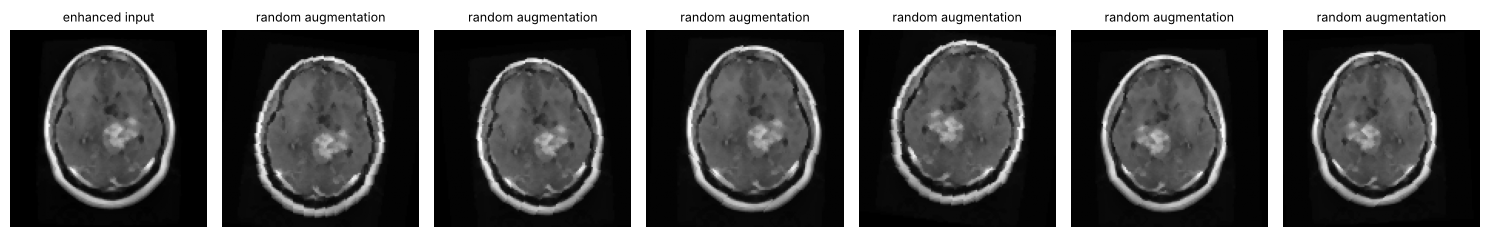

In [10]:
# What the network receives in training with the Enhanced pipeline: 1 image, 6 random augmentations
seed_everything()
i0 = ex[0]; base = torch.from_numpy(X_enh[i0]).float().div(255).unsqueeze(0)
fig, axes = plt.subplots(1, 7, figsize=(15, 2.6))
axes[0].imshow(base[0], cmap="gray"); axes[0].set_title("enhanced input", fontsize=9)
for a in axes[1:]:
    a.imshow(AUGMENT(base)[0], cmap="gray"); a.set_title("random augmentation", fontsize=9)
for a in axes: a.axis("off")
plt.tight_layout(); savefig("02_augmentation"); plt.show()

**Observation (Task 2)**
* The stratified split keeps the class proportions in all three sets (*no tumor* is 11.6–11.7 % of each set): **2,118 training, 454 validation and 455 test images**. The `assert` confirms that no image hash is shared by the training and test sets.
* Resizing to 128×128 keeps the tumors clearly visible while reducing the number of pixels 16-fold compared with 512×512, which makes training on a CPU feasible.
* The median filter removes fine speckle (at the cost of slightly softer detail); CLAHE then raises local contrast, so tumor borders and grey/white-matter boundaries become more distinct. The histograms show the effect: the Basic pixels sit in [0, 1] with a large spike at 0 (black background), while the Enhanced pixels are z-scored (training mean 0.2885, std 0.2622), giving a batch range of about −1.1 to 2.7.
* The six augmented copies of one image show that the network practically never sees the same training picture twice, which is meant to make memorising the training set harder.

## 3 · Build the CNN (Task 3)
One flexible class builds both configurations compared in §7. Every convolution block is
**Conv2d (3×3, padding 1) → [BatchNorm] → ReLU → MaxPool (2×2)**, followed by **Flatten → [Dropout] → Linear → ReLU → [Dropout] → Linear (4 logits)**.
Each layer is a separate, named module so that we can hook into it and visualize its output in §4.

| | **CNN-A: plain, 3 blocks** | **CNN-B: deeper, 4 blocks + BN + Dropout** (main model) |
|---|---|---|
| Conv channels | 16 → 32 → 64 | 16 → 32 → 64 → 128 |
| Batch normalization | no | yes (conv bias then unnecessary, set `bias=False`) |
| Feature map before Flatten | 64 × 16 × 16 = 16,384 | 128 × 8 × 8 = 8,192 |
| Classifier | FC 16,384 → 64 → 4 | Dropout 0.4 → FC 8,192 → 128 → Dropout 0.4 → FC 4 |

Both have a similar number of parameters (≈1.1 M), so the comparison is about **depth, BN and dropout**, not size.
The softmax is not inside the model: `nn.CrossEntropyLoss` applies log-softmax internally, and we apply `softmax` ourselves at prediction time.

In [11]:
class BrainTumorCNN(nn.Module):
    def __init__(self, channels=(16, 32, 64, 128), batch_norm=True, dropout=0.4, fc_units=128,
                 n_classes=4, in_channels=1, img_size=IMG_SIZE):
        super().__init__()
        feats, c_in = OrderedDict(), in_channels
        for b, c_out in enumerate(channels, start=1):
            feats[f"conv{b}"] = nn.Conv2d(c_in, c_out, kernel_size=3, padding=1, bias=not batch_norm)
            if batch_norm: feats[f"bn{b}"] = nn.BatchNorm2d(c_out)
            feats[f"relu{b}"] = nn.ReLU()
            feats[f"pool{b}"] = nn.MaxPool2d(kernel_size=2, stride=2)
            c_in = c_out
        self.features = nn.Sequential(feats)
        side = img_size // 2 ** len(channels)                    # each pool halves H and W
        head = OrderedDict(flatten=nn.Flatten())
        if dropout: head["dropout1"] = nn.Dropout(dropout)
        head["fc1"] = nn.Linear(c_in * side * side, fc_units)
        head["relu_fc"] = nn.ReLU()
        if dropout: head["dropout2"] = nn.Dropout(dropout)
        head["fc2"] = nn.Linear(fc_units, n_classes)
        self.classifier = nn.Sequential(head)

    def forward(self, x):
        return self.classifier(self.features(x))               # logits (softmax is applied in the loss)

CONFIGS = {
    "CNN-A": dict(channels=(16, 32, 64),      batch_norm=False, dropout=0.0, fc_units=64),
    "CNN-B": dict(channels=(16, 32, 64, 128), batch_norm=True,  dropout=0.4, fc_units=128),
}
def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

def layer_table(model):
    # output shape and trainable parameters of every layer (forward hooks on a dummy image)
    rows, hooks = [], []
    for name, m in model.named_modules():
        if len(list(m.children())) == 0:
            hooks.append(m.register_forward_hook(
                lambda mod, i, o, name=name: rows.append(dict(
                    layer=name.split(".")[-1], type=mod.__class__.__name__,
                    output_shape=str(tuple(o.shape)), params=count_params(mod)))))
    model.eval()
    with torch.no_grad(): model(torch.zeros(1, 1, IMG_SIZE, IMG_SIZE, device=next(model.parameters()).device))
    for h in hooks: h.remove()
    return pd.DataFrame([dict(layer="input", type="-", output_shape=str((1, 1, IMG_SIZE, IMG_SIZE)), params=0)] + rows)

for name, cfg in CONFIGS.items():
    m = BrainTumorCNN(**cfg)
    print(f"================ {name} ================"); print(m)
    display(layer_table(m))
    print(f"{name}: trainable parameters = {count_params(m):,}\n")

================ CNN-A ================
BrainTumorCNN(
  (features): Sequential(
    (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (relu1): ReLU()
    (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (relu2): ReLU()
    (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (relu3): ReLU()
    (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (flatten): Flatten(start_dim=1, end_dim=-1)
    (fc1): Linear(in_features=16384, out_features=64, bias=True)
    (relu_fc): ReLU()
    (fc2): Linear(in_features=64, out_features=4, bias=True)
  )
)


,layer,type,output_shape,params
0,input,-,"(1, 1, 128, 128)",0
1,conv1,Conv2d,"(1, 16, 128, 128)",160
2,relu1,ReLU,"(1, 16, 128, 128)",0
3,pool1,MaxPool2d,"(1, 16, 64, 64)",0
4,conv2,Conv2d,"(1, 32, 64, 64)",4640
5,relu2,ReLU,"(1, 32, 64, 64)",0
6,pool2,MaxPool2d,"(1, 32, 32, 32)",0
7,conv3,Conv2d,"(1, 64, 32, 32)",18496
8,relu3,ReLU,"(1, 64, 32, 32)",0
9,pool3,MaxPool2d,"(1, 64, 16, 16)",0


CNN-A: trainable parameters = 1,072,196

================ CNN-B ================
BrainTumorCNN(
  (features): Sequential(
    (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu1): ReLU()
    (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu2): ReLU()
    (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn3): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu3): ReLU()
    (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilat

,layer,type,output_shape,params
0,input,-,"(1, 1, 128, 128)",0
1,conv1,Conv2d,"(1, 16, 128, 128)",144
2,bn1,BatchNorm2d,"(1, 16, 128, 128)",32
3,relu1,ReLU,"(1, 16, 128, 128)",0
4,pool1,MaxPool2d,"(1, 16, 64, 64)",0
5,conv2,Conv2d,"(1, 32, 64, 64)",4608
6,bn2,BatchNorm2d,"(1, 32, 64, 64)",64
7,relu2,ReLU,"(1, 32, 64, 64)",0
8,pool2,MaxPool2d,"(1, 32, 32, 32)",0
9,conv3,Conv2d,"(1, 64, 32, 32)",18432


CNN-B: trainable parameters = 1,146,612



**Checking two parameter counts by hand** (formula in §8): `conv1` of CNN-A: (3·3·1 + 1)·16 = **160**. `fc1` of CNN-B: 8,192·128 + 128 = **1,048,704**, so the fully connected layer holds about 91 % of all CNN-B weights, while the four convolution layers together need fewer than 100 k. Pooling, ReLU, Flatten and Dropout have **no** parameters.

## 4 · Visualize every layer (Task 4)
A **forward hook** is attached to every layer; one image is passed through the network and the output of each layer is stored. Shown below:
1. the **input image** (after the Enhanced preprocessing),
2. a table with the **output shape** (and simple statistics) of **every** layer,
3. the first 8 feature maps of every **convolution**, **batch-norm**, **ReLU activation** and **pooling** output,
4. the flattened vector, the fully connected outputs and the final class probabilities.

Here the network still has its **random initial weights** (untrained). The same figures are repeated in §5.1 after training, so the two can be compared.

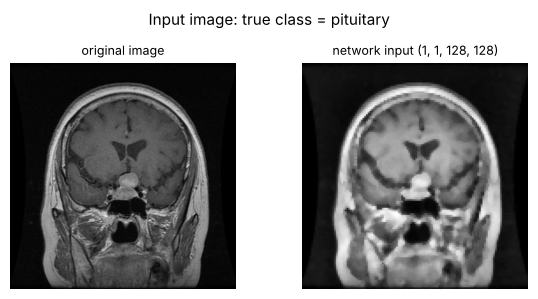

Output shape of every layer (CNN-B, initial weights):


,layer,output_shape,mean,std,zeros_pct
0,input,"(1, 1, 128, 128)",0.157,1.041,0.000
1,conv1,"(1, 16, 128, 128)",-0.030,0.746,0.000
2,bn1,"(1, 16, 128, 128)",-0.030,0.746,0.000
3,relu1,"(1, 16, 128, 128)",0.251,0.418,51.326
4,pool1,"(1, 16, 64, 64)",0.300,0.452,42.953
5,conv2,"(1, 32, 64, 64)",-0.012,0.347,0.000
6,bn2,"(1, 32, 64, 64)",-0.012,0.347,0.000
7,relu2,"(1, 32, 64, 64)",0.128,0.192,50.425
8,pool2,"(1, 32, 32, 32)",0.168,0.221,41.949
9,conv3,"(1, 64, 32, 32)",-0.006,0.148,0.000


In [12]:
def get_activations(model, x):
    acts, hooks = OrderedDict(), []
    for name, m in model.named_modules():
        if len(list(m.children())) == 0:
            hooks.append(m.register_forward_hook(
                lambda mod, i, o, name=name: acts.__setitem__(name.split(".")[-1], o.detach().cpu())))
    model.eval()
    with torch.no_grad(): logits = model(x.to(DEVICE))
    for h in hooks: h.remove()
    acts["softmax"] = F.softmax(logits, dim=1).cpu()
    return acts

def activation_table(acts, x):
    rows = [dict(layer="input", output_shape=str(tuple(x.shape)), mean=x.mean().item(), std=x.std().item(),
                 zeros_pct=100 * (x == 0).float().mean().item())]
    for k, v in acts.items():
        rows.append(dict(layer=k, output_shape=str(tuple(v.shape)), mean=v.mean().item(), std=v.std().item(),
                         zeros_pct=100 * (v == 0).float().mean().item()))
    return pd.DataFrame(rows).round(3)

def plot_feature_maps(acts, n_maps=8, title="", fname=None):
    names = [k for k, v in acts.items() if v.ndim == 4]                 # conv / bn / relu / pool outputs
    H = 1.45 * len(names) + 0.6
    fig, axes = plt.subplots(len(names), n_maps, figsize=(1.45 * n_maps + 1.6, H))
    for r, k in enumerate(names):
        fm = acts[k][0]
        for c in range(n_maps):
            a = axes[r, c]; a.imshow(fm[c], cmap="viridis"); a.set_xticks([]); a.set_yticks([])
        kind = "".join(ch for ch in k if ch.isalpha())
        col = {"conv": "#2457D6", "bn": "#7A7A7A", "relu": "#B7600A", "pool": "#0E7C6B"}[kind]
        axes[r, 0].set_ylabel(f"{k}\n{fm.shape[0]}×{fm.shape[1]}×{fm.shape[2]}", rotation=0, ha="right",
                              va="center", fontsize=9, color=col, fontweight="bold")
    for c in range(n_maps): axes[0, c].set_title(f"map {c}", fontsize=8)
    fig.suptitle(title, fontsize=12, y=1 - 0.12 / H)
    plt.subplots_adjust(left=0.12, right=0.99, top=1 - 0.6 / H, bottom=0.01, wspace=0.05, hspace=0.08)
    if fname: savefig(fname)
    plt.show()

def plot_head(acts, title="", fname=None):
    keys = [k for k in ["flatten", "fc1", "relu_fc", "fc2", "softmax"] if k in acts]
    fig, axes = plt.subplots(1, len(keys), figsize=(3.3 * len(keys), 2.8))
    for a, k in zip(axes, keys):
        v = acts[k][0].numpy()
        if k == "flatten": a.plot(v, lw=0.4, color="#2457D6")
        elif k in ("fc2", "softmax"): a.bar(NAMES, v, color=COLORS); a.tick_params(axis="x", rotation=30, labelsize=8)
        else: a.bar(range(len(v)), v, color="#B7600A", width=1.0)
        a.set_title(f"{k}  {tuple(acts[k].shape)}", fontsize=9)
    axes[-1].set_ylim(0, 1)
    fig.suptitle(title, fontsize=11); plt.tight_layout()
    if fname: savefig(fname)
    plt.show()

def to_input(i, pipeline="Enhanced"):
    p = PIPELINES[pipeline]
    return ((torch.from_numpy(p["images"][i]).float() / 255 - p["mean"]) / p["std"])[None, None]

# one test image (a pituitary tumor) is used for all layer visualizations
VIS_IDX = int(SPLITS["test"][y_all[SPLITS["test"]] == 3][0])
x_vis = to_input(VIS_IDX)

seed_everything()
model_init = BrainTumorCNN(**CONFIGS["CNN-B"]).to(DEVICE)        # random initial weights
acts0 = get_activations(model_init, x_vis)

fig, ax = plt.subplots(1, 2, figsize=(6, 3))
ax[0].imshow(load_gray(df.path[VIS_IDX]), cmap="gray"); ax[0].set_title("original image", fontsize=9)
ax[1].imshow(x_vis[0, 0], cmap="gray"); ax[1].set_title(f"network input {tuple(x_vis.shape)}", fontsize=9)
for a in ax: a.axis("off")
fig.suptitle(f"Input image: true class = {NAMES[y_all[VIS_IDX]]}", fontsize=11); plt.tight_layout(); savefig("04_input"); plt.show()

print("Output shape of every layer (CNN-B, initial weights):")
display(activation_table(acts0, x_vis))

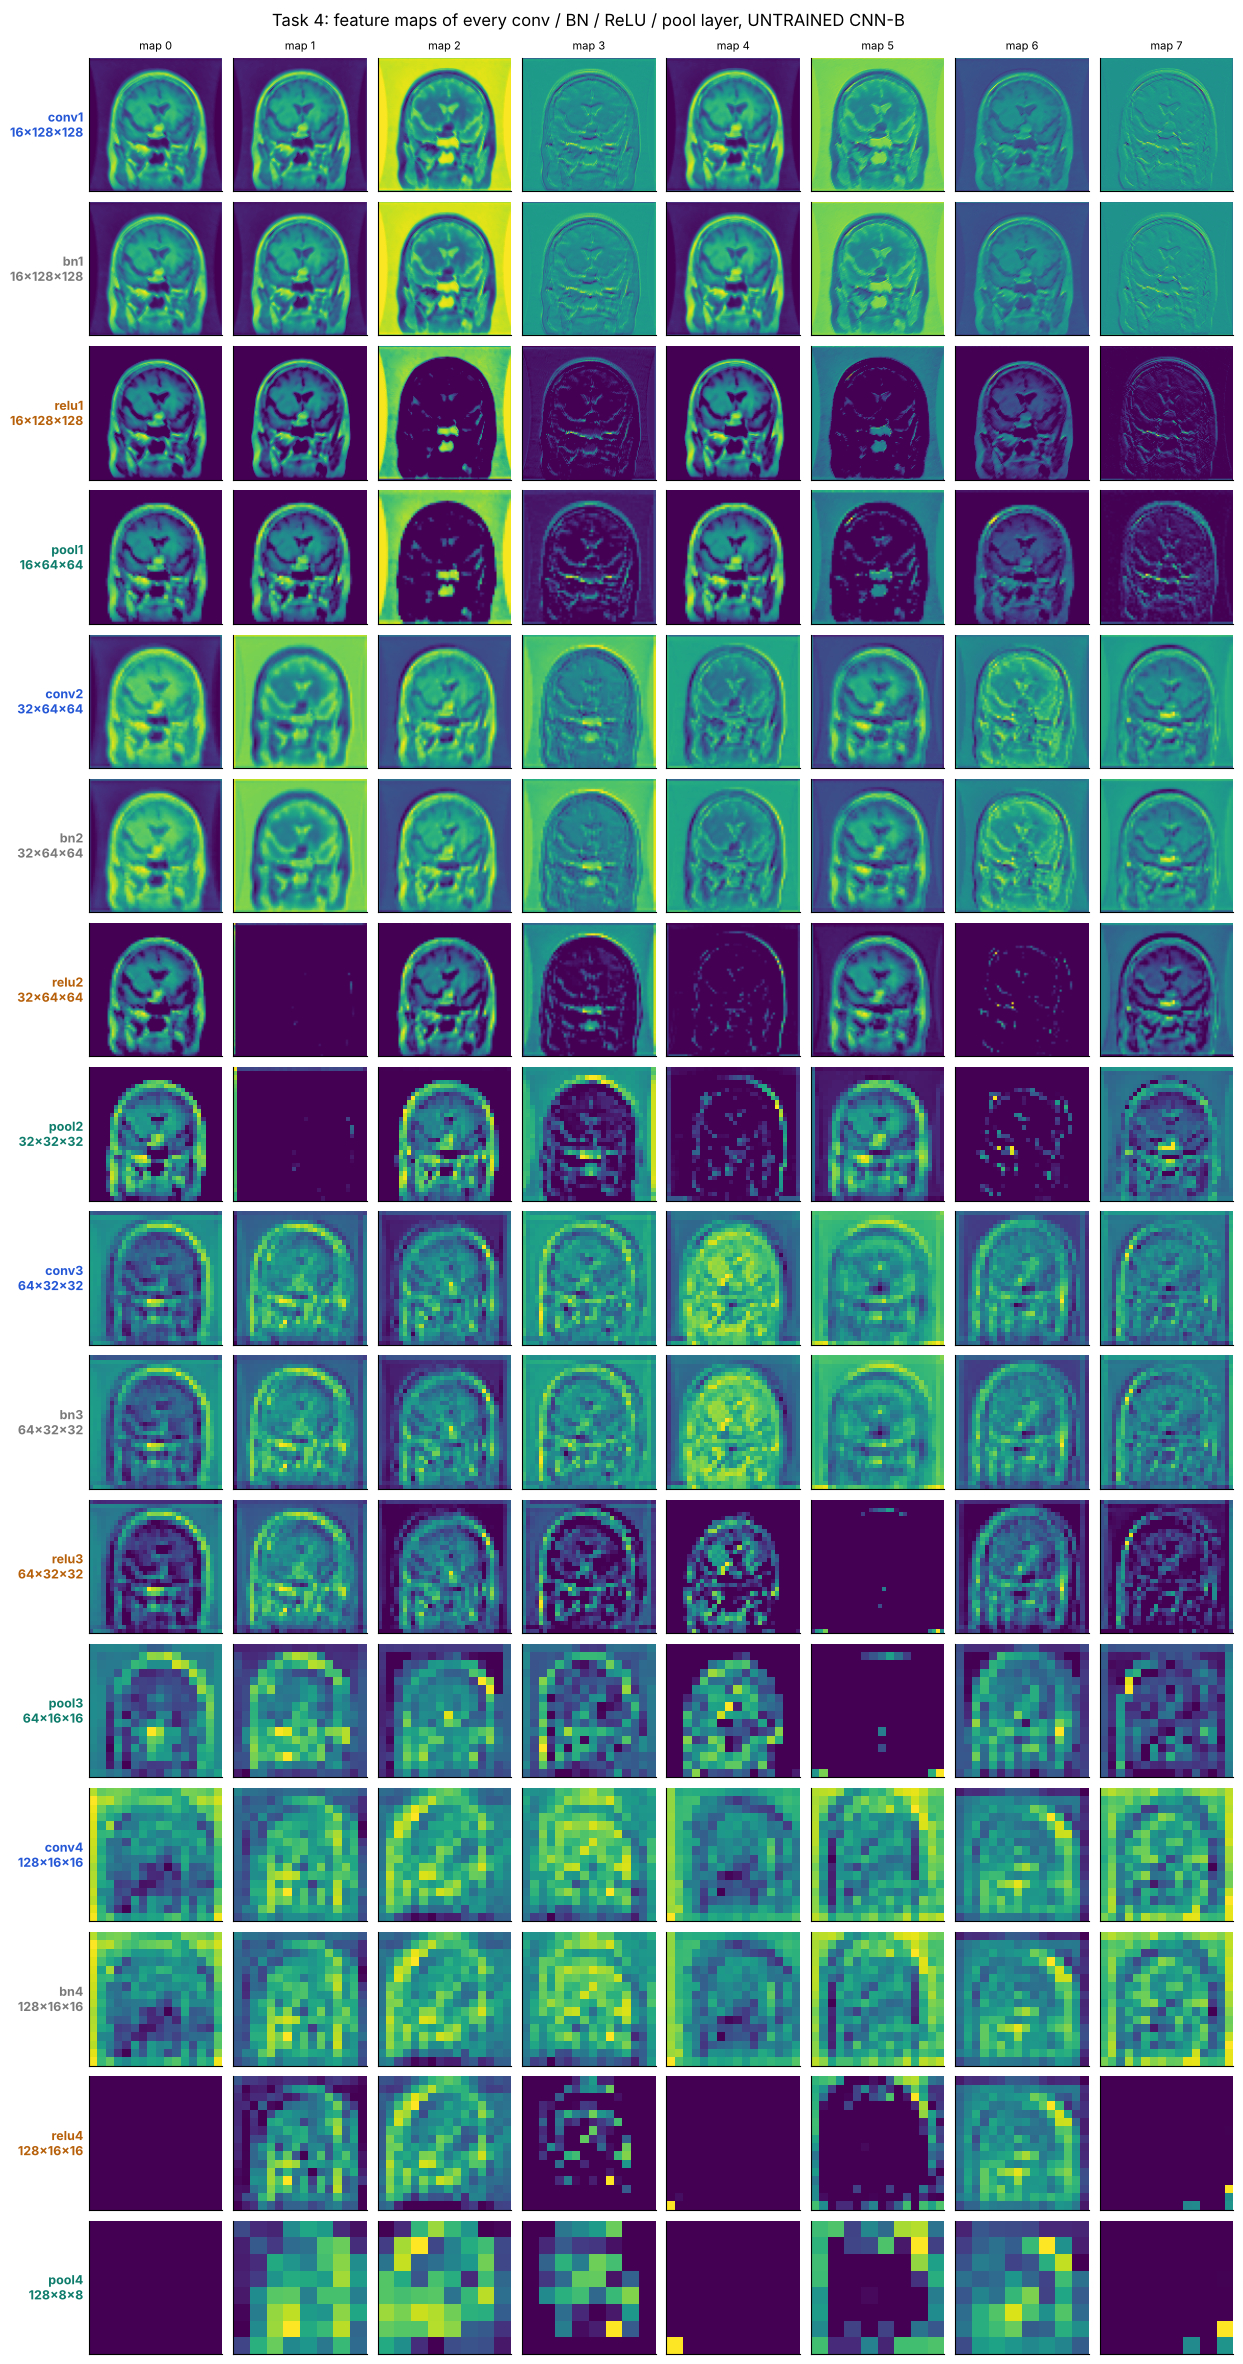

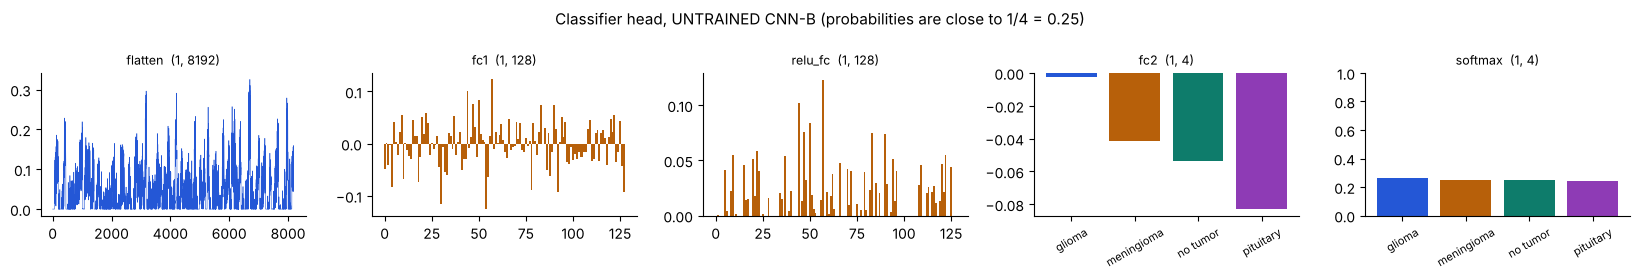

In [13]:
plot_feature_maps(acts0, title="Task 4: feature maps of every conv / BN / ReLU / pool layer, UNTRAINED CNN-B",
                  fname="04_feature_maps_untrained")
plot_head(acts0, title="Classifier head, UNTRAINED CNN-B (probabilities are close to 1/4 = 0.25)",
          fname="04_head_untrained")

**Observation (Task 4, untrained network)**
* The output shapes follow $O = \lfloor (N + 2P - F)/S \rfloor + 1$: every 3×3 convolution with padding 1 keeps the size, every 2×2 max-pool halves it (128 → 64 → 32 → 16 → 8), while the number of channels grows 1 → 16 → 32 → 64 → 128. Flatten gives 128·8·8 = 8,192 values, `fc1` 128 and `fc2` 4.
* Even random 3×3 filters already produce edge- and brightness-like maps in the first block: any small filter acts as a crude local edge or smoothing operator.
* **ReLU** sets about half of the values to exactly zero (47–52 % in every block). **Pooling** lowers the zero fraction (33–43 %) because a 2×2 window survives if any of its four values is positive.
* Some deep maps are (almost) completely dark (e.g. `relu4` maps 0, 4 and 7): those random filters hardly respond to this image.
* The **BN** rows look identical to the conv rows: an untrained BN layer in evaluation mode uses its initial statistics (mean 0, variance 1, γ = 1, β = 0) and is therefore the identity.
* The untrained softmax gives ≈ 0.25 to every class: the network knows nothing yet.

## 5 · Train the model (Task 5)
* **Loss:** cross-entropy. **Optimizer:** Adam, learning rate 1e-3, weight decay 1e-4. **Batch size:** 32.
* **ReduceLROnPlateau:** halves the learning rate when the validation loss has not improved for 3 epochs.
* **Early stopping:** stop after 8 epochs without a new best validation loss (at most 60 epochs) and **restore the weights of the best epoch**. The limit of 60 was chosen after a first run with a limit of 35 ended while the *validation* loss of the main model was still falling; the test set played no part in that choice.
* Training accuracy is measured on the (augmented) mini-batches during the epoch; validation is measured in `eval` mode (no dropout, no augmentation).

Main experiment: **CNN-B + Enhanced preprocessing.**

In [14]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            logits = model(xb); loss = criterion(logits, yb)
            if training:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * len(yb); correct += (logits.argmax(1) == yb).sum().item(); n += len(yb)
    return total_loss / n, correct / n

def train_model(config, pipeline, max_epochs=MAX_EPOCHS, lr=LR, patience=PATIENCE, verbose=True):
    seed_everything()                                   # identical initialization / shuffling for every run
    loaders = make_loaders(pipeline)
    model = BrainTumorCNN(**CONFIGS[config]).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "lr"]}
    best_loss, best_state, best_epoch, wait, t0 = np.inf, None, 0, 0, time.time()
    print(f"--- {config} + {pipeline} preprocessing ({count_params(model):,} parameters) ---")
    for ep in range(1, max_epochs + 1):
        lr_now = optimizer.param_groups[0]["lr"]
        tl, ta = run_epoch(model, loaders["train"], criterion, optimizer)
        vl, va = run_epoch(model, loaders["val"], criterion)
        scheduler.step(vl)
        for k, v in zip(hist, [tl, ta, vl, va, lr_now]): hist[k].append(v)
        if vl < best_loss: best_loss, best_state, best_epoch, wait = vl, copy.deepcopy(model.state_dict()), ep, 0
        else: wait += 1
        if verbose:
            print(f"epoch {ep:2d} | train loss {tl:.4f} acc {ta:.3f} | val loss {vl:.4f} acc {va:.3f} "
                  f"| lr {lr_now:.1e} | {time.time() - t0:4.0f}s{'  <- best' if best_epoch == ep else ''}")
        if wait >= patience:
            print(f"early stopping after epoch {ep}; restoring best epoch {best_epoch}"); break
    model.load_state_dict(best_state)
    return dict(model=model, history=hist, best_epoch=best_epoch, epochs_run=ep,
                time=time.time() - t0, loaders=loaders, config=config, pipeline=pipeline)

RUNS = {}
RUNS[("Enhanced", "CNN-B")] = main = train_model("CNN-B", "Enhanced")
print(f"training time: {main['time']:.0f} s")
torch.save(main["model"].state_dict(), "cnn_b_enhanced_best.pt")      # best weights of the main model

--- CNN-B + Enhanced preprocessing (1,146,612 parameters) ---


epoch  1 | train loss 1.1711 acc 0.528 | val loss 0.8663 acc 0.648 | lr 1.0e-03 |   12s  <- best


epoch  2 | train loss 0.8660 acc 0.642 | val loss 0.8299 acc 0.670 | lr 1.0e-03 |   24s  <- best


epoch  3 | train loss 0.8229 acc 0.666 | val loss 0.6772 acc 0.720 | lr 1.0e-03 |   36s  <- best


epoch  4 | train loss 0.7782 acc 0.677 | val loss 0.7077 acc 0.698 | lr 1.0e-03 |   48s


epoch  5 | train loss 0.7492 acc 0.672 | val loss 0.6132 acc 0.694 | lr 1.0e-03 |   60s  <- best


... (51 outputs left out)

epoch 57 | train loss 0.3034 acc 0.889 | val loss 0.2887 acc 0.899 | lr 6.3e-05 |  728s


epoch 58 | train loss 0.2985 acc 0.880 | val loss 0.2870 acc 0.892 | lr 6.3e-05 |  741s


epoch 59 | train loss 0.3047 acc 0.881 | val loss 0.2831 acc 0.901 | lr 6.3e-05 |  754s  <- best


epoch 60 | train loss 0.3063 acc 0.876 | val loss 0.2801 acc 0.896 | lr 6.3e-05 |  767s  <- best
training time: 767 s


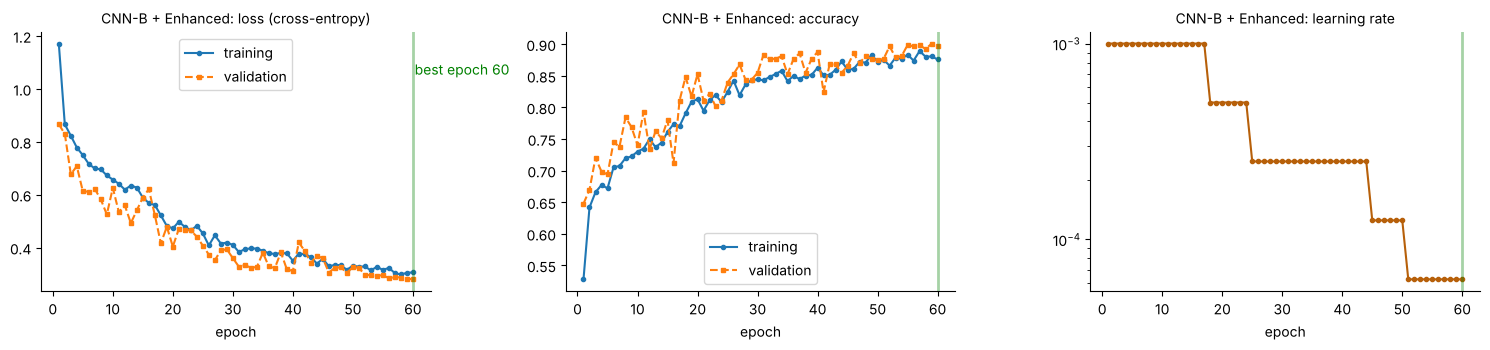

Training and validation accuracy / loss per epoch:


,train_loss,train_acc,val_loss,val_acc,lr
epoch,,,,,
1,1.1711,0.5279,0.8663,0.6476,0.0010
2,0.8660,0.6416,0.8299,0.6696,0.0010
3,0.8229,0.6657,0.6772,0.7203,0.0010
4,0.7782,0.6771,0.7077,0.6982,0.0010
5,0.7492,0.6719,0.6132,0.6938,0.0010
6,0.7160,0.7049,0.6111,0.7445,0.0010
7,0.6990,0.7073,0.6218,0.7379,0.0010
8,0.6956,0.7195,0.5819,0.7841,0.0010
9,0.6727,0.7224,0.5254,0.7687,0.0010


Best epoch 60: train loss 0.3063, train acc 0.876 | val loss 0.2801, val acc 0.896


In [15]:
def plot_history(run, fname=None):
    h, b = run["history"], run["best_epoch"]
    ep = np.arange(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
    ax[0].plot(ep, h["train_loss"], "o-", ms=3, label="training"); ax[0].plot(ep, h["val_loss"], "s--", ms=3, label="validation")
    ax[1].plot(ep, h["train_acc"], "o-", ms=3, label="training");  ax[1].plot(ep, h["val_acc"], "s--", ms=3, label="validation")
    ax[2].plot(ep, h["lr"], "o-", ms=3, color="#B7600A"); ax[2].set_yscale("log")
    for a, t in zip(ax, ["loss (cross-entropy)", "accuracy", "learning rate"]):
        a.set_title(f"{run['config']} + {run['pipeline']}: {t}", fontsize=10); a.set_xlabel("epoch")
        a.axvline(b, color="green", alpha=.35, lw=2)
    ax[0].legend(); ax[1].legend(); ax[0].text(b + .3, max(h["train_loss"]) * .9, f"best epoch {b}", color="green")
    plt.tight_layout()
    if fname: savefig(fname)
    plt.show()

plot_history(main, "05_learning_curves_main")
h = pd.DataFrame(main["history"]); h.index = np.arange(1, len(h) + 1); h.index.name = "epoch"
print("Training and validation accuracy / loss per epoch:")
display(h.round(4))
b = main["best_epoch"] - 1
print(f"Best epoch {b + 1}: train loss {h.train_loss.iloc[b]:.4f}, train acc {h.train_acc.iloc[b]:.3f} | "
      f"val loss {h.val_loss.iloc[b]:.4f}, val acc {h.val_acc.iloc[b]:.3f}")

**Observation (Task 5)**
* Training used all 60 epochs; the lowest validation loss (**0.280, validation accuracy 0.896**) was reached in the last epoch, so early stopping did not trigger. `ReduceLROnPlateau` lowered the learning rate four times (epochs 18, 25, 45 and 51, from 1e-3 to 6.25e-5), and each reduction made the curves smoother and lower.
* In the last 9 epochs the validation loss improved only from 0.297 to 0.280: the model is close to convergence, and a longer budget would probably bring only small gains.
* Training and validation curves stay close, and validation accuracy is *higher* than training accuracy in 53 of 60 epochs. This is not leakage: training accuracy is measured on augmented images with dropout switched on, which is harder than the clean validation images. Evaluated without augmentation, the final training accuracy is 0.957 (Table 1 in §7), a moderate train–validation gap of 6 points.
* The validation curve is noisy during the first 20 epochs (e.g. 0.711 at epoch 16), while the learning rate is still high and the validation set is small (454 images).

### 5.1 Every layer again, now with the **trained** weights (Task 4 continued)
Same image as in §4, same code, but with the weights learned in §5.

Output shape and statistics of every layer (CNN-B, trained):


,layer,output_shape,mean,std,zeros_pct
0,input,"(1, 1, 128, 128)",0.157,1.041,0.000
1,conv1,"(1, 16, 128, 128)",-0.007,0.731,0.000
2,bn1,"(1, 16, 128, 128)",-0.064,1.009,0.000
3,relu1,"(1, 16, 128, 128)",0.362,0.570,53.548
4,pool1,"(1, 16, 64, 64)",0.498,0.701,42.946
5,conv2,"(1, 32, 64, 64)",-0.031,1.482,0.000
6,bn2,"(1, 32, 64, 64)",-0.051,0.959,0.000
7,relu2,"(1, 32, 64, 64)",0.346,0.546,50.938
8,pool2,"(1, 32, 32, 32)",0.535,0.685,37.500
9,conv3,"(1, 64, 32, 32)",-0.055,1.325,0.000


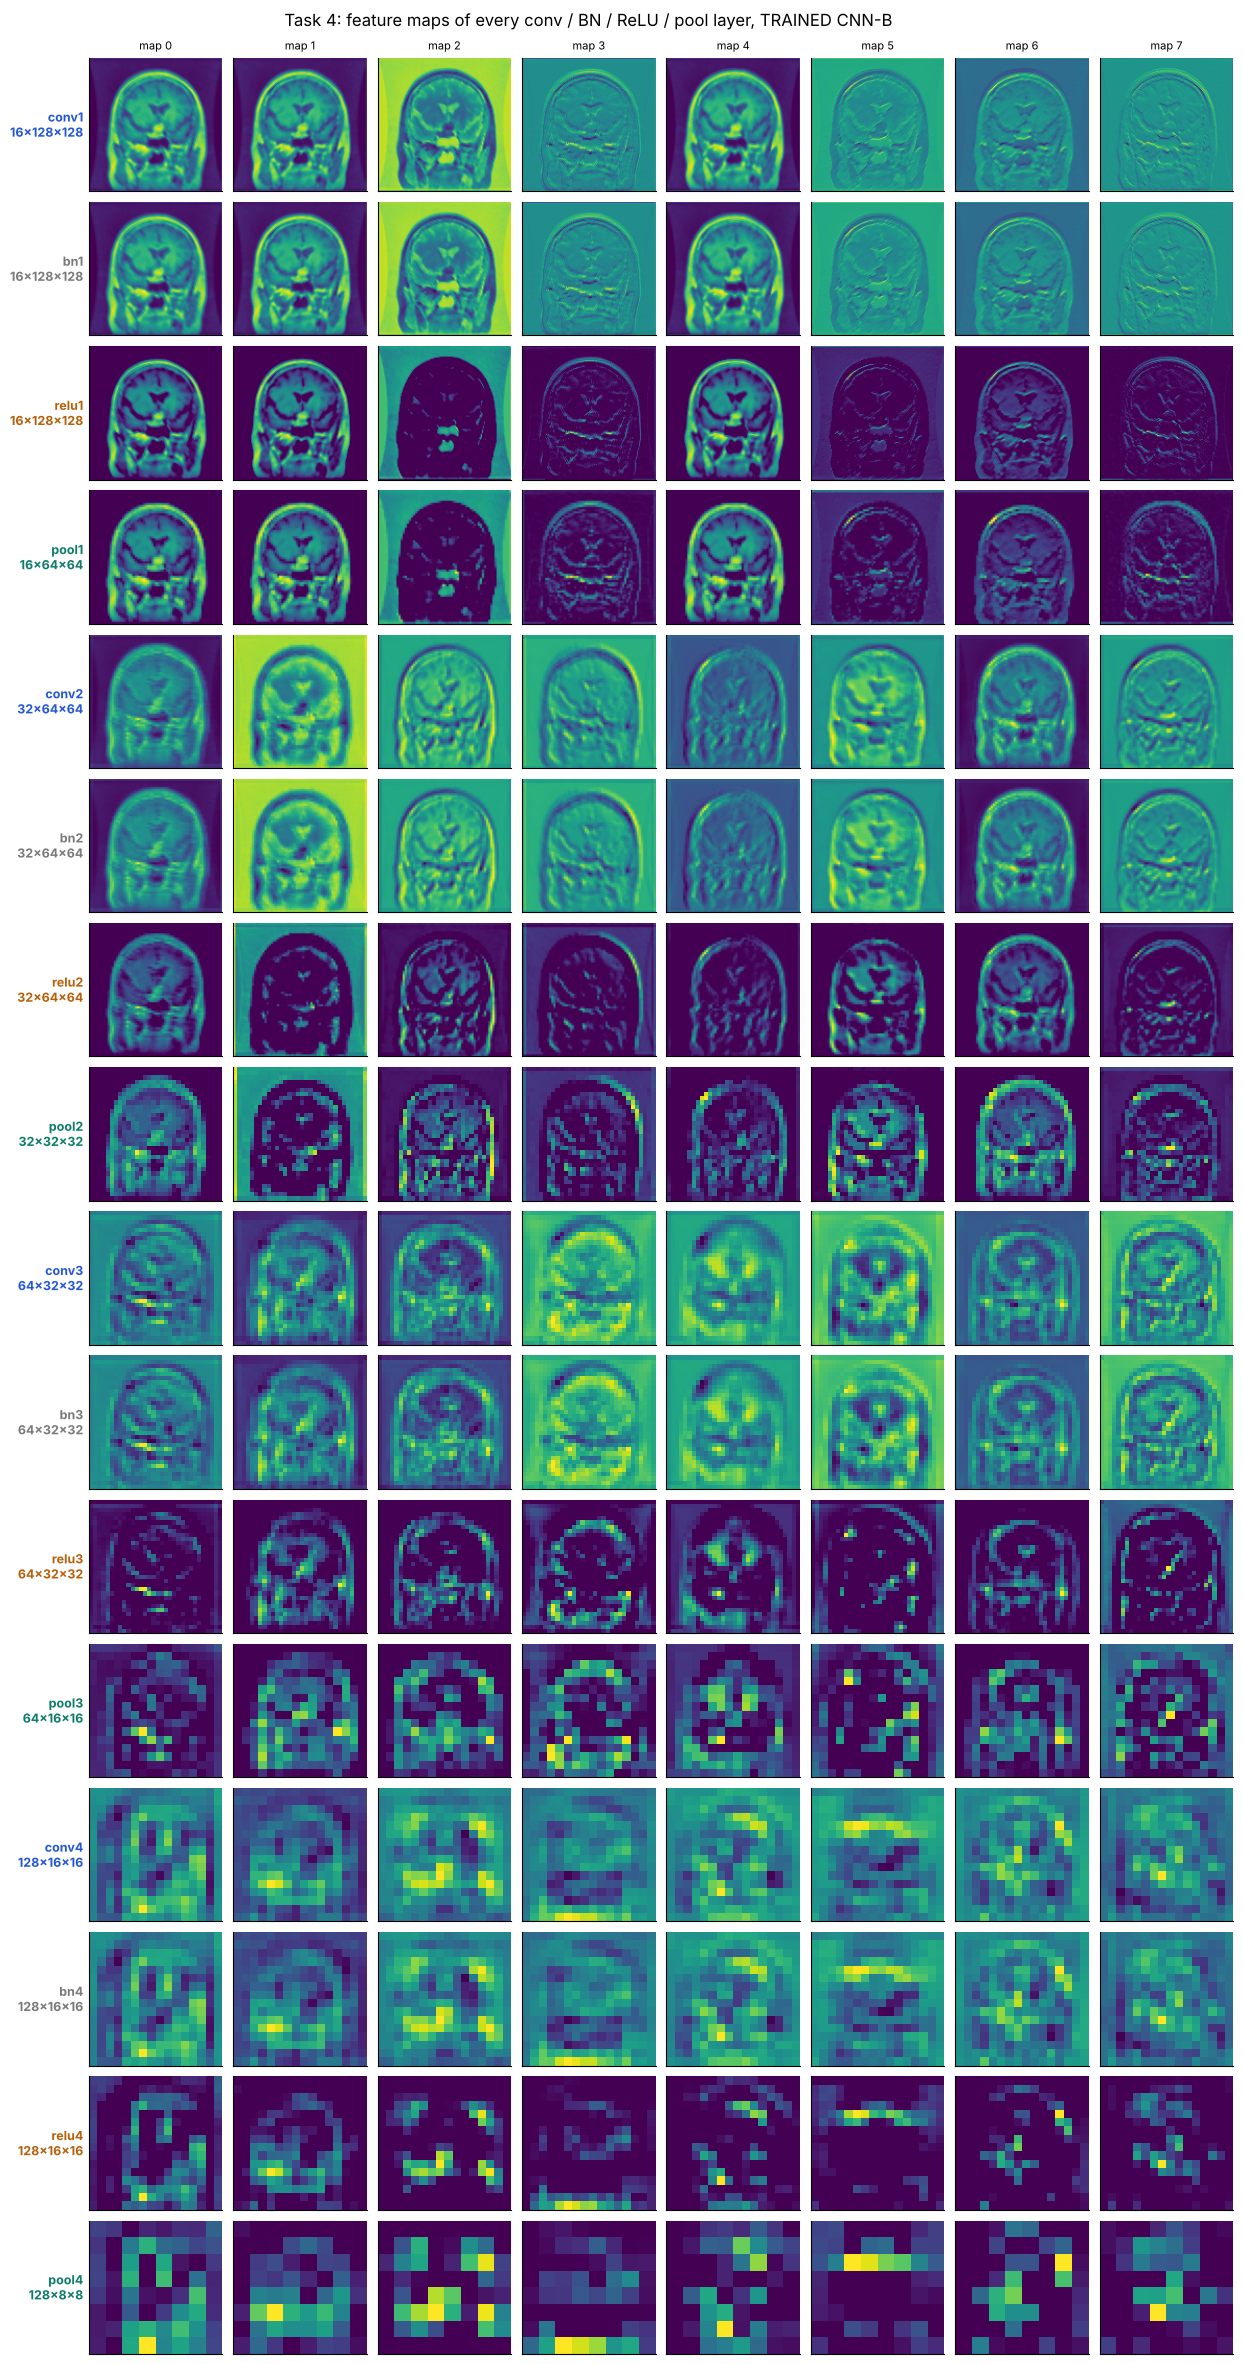

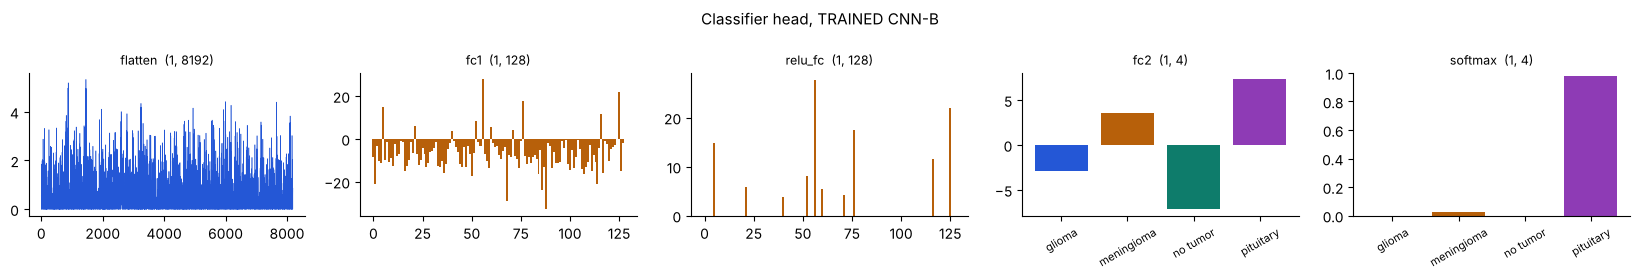

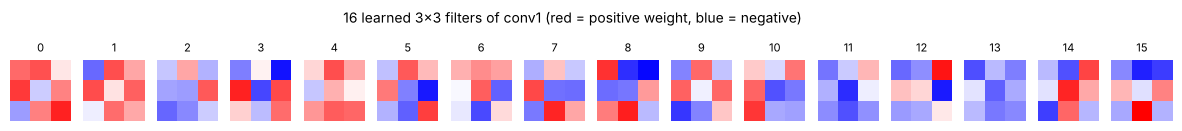

Percentage of exactly-zero values after each ReLU / pooling layer:


,untrained,trained
layer,,
relu1,51.3,53.5
pool1,43.0,42.9
relu2,50.4,50.9
pool2,41.9,37.5
relu3,51.5,51.4
pool3,38.2,31.6
relu4,47.3,59.8
pool4,33.0,33.7
relu_fc,49.2,92.2


In [16]:
acts1 = get_activations(main["model"], x_vis)
print("Output shape and statistics of every layer (CNN-B, trained):")
display(activation_table(acts1, x_vis))
plot_feature_maps(acts1, title="Task 4: feature maps of every conv / BN / ReLU / pool layer, TRAINED CNN-B",
                  fname="05_feature_maps_trained")
plot_head(acts1, title="Classifier head, TRAINED CNN-B", fname="05_head_trained")

# The 16 learned 3x3 filters of the first convolution layer
w = main["model"].features.conv1.weight.detach().cpu()[:, 0]
fig, axes = plt.subplots(1, 16, figsize=(15, 1.3))
for k, a in enumerate(axes): a.imshow(w[k], cmap="bwr", vmin=-w.abs().max(), vmax=w.abs().max()); a.axis("off"); a.set_title(k, fontsize=8)
fig.suptitle("16 learned 3×3 filters of conv1 (red = positive weight, blue = negative)", fontsize=10, y=1.12)
savefig("05_conv1_filters"); plt.show()

z = pd.DataFrame({"untrained": activation_table(acts0, x_vis).set_index("layer").zeros_pct,
                  "trained": activation_table(acts1, x_vis).set_index("layer").zeros_pct})
print("Percentage of exactly-zero values after each ReLU / pooling layer:")
display(z.loc[[k for k in z.index if k.startswith(("relu", "pool"))]].round(1))

**Observation (Task 4, trained network)**
* The **first block** looks almost the same as before training: low-level edge and intensity detectors are useful from the start and change little. The learned `conv1` filters include oriented edge detectors (e.g. filter 15: negative weights on top, positive at the bottom, i.e. a horizontal-edge detector) and mostly positive filters that act as local brightness or smoothing detectors (e.g. filters 0 and 4).
* The **deep layers changed most**. Untrained `conv4` maps still show the outline of the head; after training, the 16×16 and 8×8 maps (`relu4`, `pool4`) respond to a few compact regions. Each deep map is no longer a picture but an answer to "is pattern *k* present here?".
* Sparsity grows with depth after training: 59.8 % of the `relu4` values are zero (47.3 % untrained), and **92.2 % of the 128 `fc1` units are zero** (49.2 % untrained), so only about 10 fully connected units carry the decision for this image.
* The softmax now gives about **0.97 to *pituitary***, the correct class (0.25 before training).

## 6 · Test the model (Task 6)
The test set (never used for training or for choosing epochs) is evaluated **once** with the best weights of the main model.
Precision, recall and F1 are reported per class and as the **macro average** (unweighted mean over the 4 classes, so the smaller *no tumor* class counts as much as the others).

In [17]:
@torch.no_grad()
def predict(model, loader):
    model.eval(); logits, ys = [], []
    for xb, yb in loader:
        logits.append(model(xb.to(DEVICE)).cpu()); ys.append(yb)
    logits, ys = torch.cat(logits), torch.cat(ys)
    return F.softmax(logits, 1).numpy(), ys.numpy(), F.cross_entropy(logits, ys).item()

def wilson_ci(k, n, z=1.96):          # 95 % confidence interval of a proportion (accuracy)
    p = k / n; d = 1 + z * z / n; c = p + z * z / (2 * n); h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return (c - h) / d, (c + h) / d

probs, y_test, test_loss = predict(main["model"], main["loaders"]["test"])
y_pred = probs.argmax(1)
acc = accuracy_score(y_test, y_pred)
P, R, F1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)
lo, hi = wilson_ci((y_pred == y_test).sum(), len(y_test))
print(f"TEST  (n = {len(y_test)})  loss {test_loss:.4f}")
print(f"accuracy        {acc:.4f}   (95% CI {lo:.3f} to {hi:.3f})")
print(f"macro precision {P:.4f}\nmacro recall    {R:.4f}\nmacro F1-score  {F1:.4f}\n")
rep = pd.DataFrame(classification_report(y_test, y_pred, target_names=NAMES, output_dict=True, zero_division=0)).T
display(rep.round(4))

TEST  (n = 455)  loss 0.3641
accuracy        0.8725   (95% CI 0.839 to 0.900)
macro precision 0.8623
macro recall    0.8741
macro F1-score  0.8667



,precision,recall,f1-score,support
glioma,0.9091,0.8088,0.8560,136.0000
meningioma,0.8273,0.8273,0.8273,139.0000
no tumor,0.7931,0.8679,0.8288,53.0000
pituitary,0.9197,0.9921,0.9545,127.0000
accuracy,0.8725,0.8725,0.8725,0.8725
macro avg,0.8623,0.8741,0.8667,455.0000
weighted avg,0.8736,0.8725,0.8716,455.0000


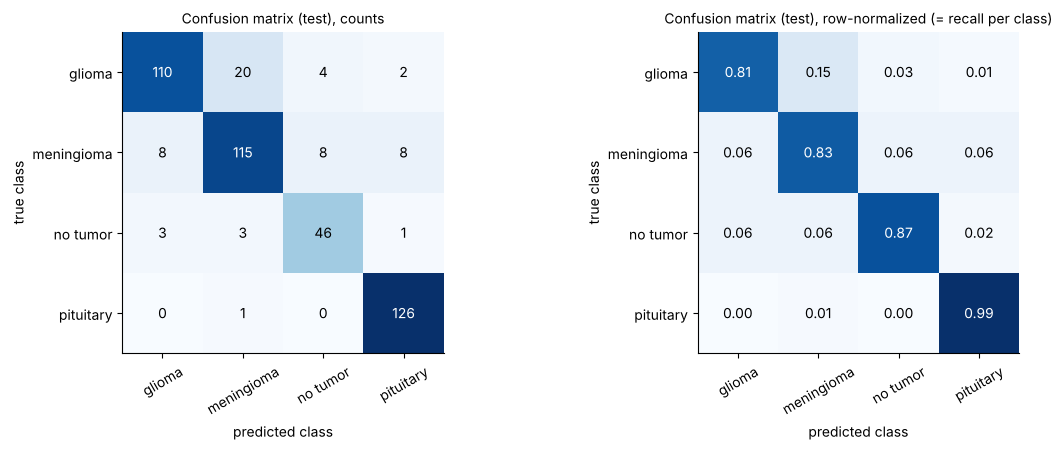

In [18]:
cm = confusion_matrix(y_test, y_pred)
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for a, M, t, fmt in [(ax[0], cm, "counts", "d"), (ax[1], cmn, "row-normalized (= recall per class)", ".2f")]:
    a.imshow(M, cmap="Blues")
    a.set_xticks(range(4)); a.set_xticklabels(NAMES, rotation=30); a.set_yticks(range(4)); a.set_yticklabels(NAMES)
    a.set_xlabel("predicted class"); a.set_ylabel("true class"); a.set_title(f"Confusion matrix (test), {t}", fontsize=10)
    for i in range(4):
        for j in range(4):
            a.text(j, i, format(M[i, j], fmt), ha="center", va="center", color="white" if M[i, j] > M.max() / 2 else "black")
plt.tight_layout(); savefig("06_confusion_matrix"); plt.show()

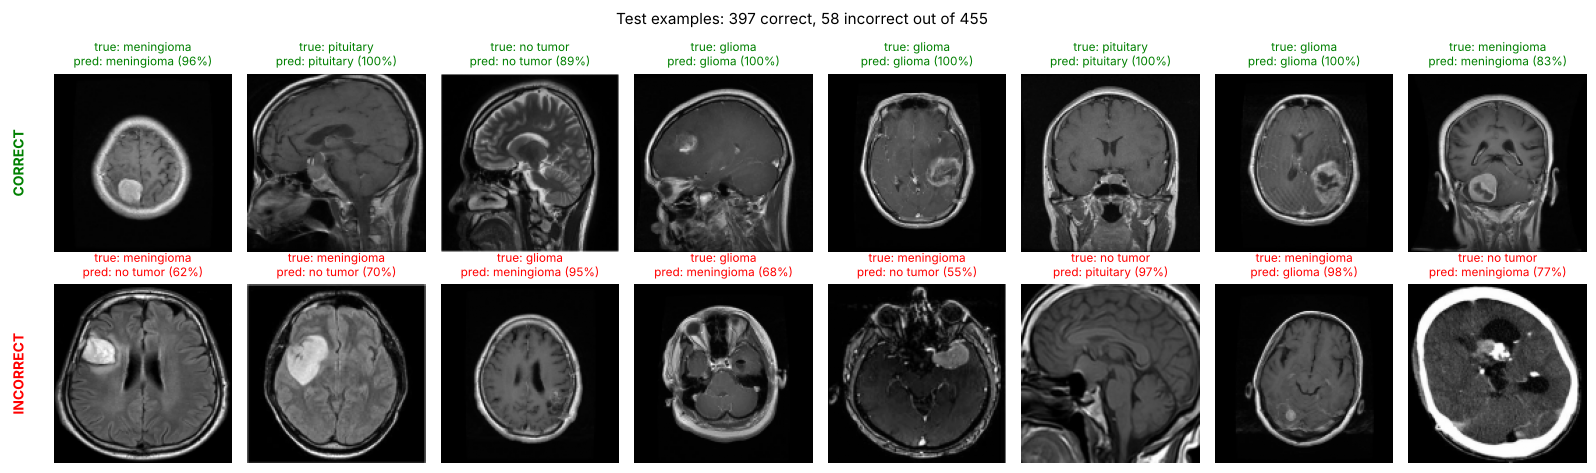

Mean softmax confidence:


,count,mean,50%,min
result,,,,
correct,397.0,0.915,0.987,0.449
incorrect,58.0,0.706,0.703,0.410


In [19]:
test_ids = SPLITS["test"]
correct = np.where(y_pred == y_test)[0]; wrong = np.where(y_pred != y_test)[0]
rng = np.random.RandomState(SEED)
show = [("correct", rng.choice(correct, 8, replace=False)), ("incorrect", rng.choice(wrong, min(8, len(wrong)), replace=False))]
fig, axes = plt.subplots(2, 8, figsize=(16, 4.9))
for r, (kind, sel) in enumerate(show):
    for c in range(8):
        a = axes[r, c]; a.axis("off")
        if c >= len(sel): continue
        j = sel[c]
        a.imshow(X_basic[test_ids[j]], cmap="gray")
        a.set_title(f"true: {NAMES[y_test[j]]}\npred: {NAMES[y_pred[j]]} ({probs[j].max():.0%})", fontsize=8.5,
                    color="green" if kind == "correct" else "red")
axes[0, 0].text(-0.15, .5, "CORRECT", transform=axes[0, 0].transAxes, rotation=90, va="center", ha="right", color="green", fontweight="bold")
axes[1, 0].text(-0.15, .5, "INCORRECT", transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right", color="red", fontweight="bold")
fig.suptitle(f"Test examples: {len(correct)} correct, {len(wrong)} incorrect out of {len(y_test)}", fontsize=11)
plt.tight_layout(); savefig("06_examples"); plt.show()

conf = pd.DataFrame({"confidence": probs.max(1), "result": np.where(y_pred == y_test, "correct", "incorrect")})
print("Mean softmax confidence:"); display(conf.groupby("result").confidence.describe()[["count", "mean", "50%", "min"]].round(3))

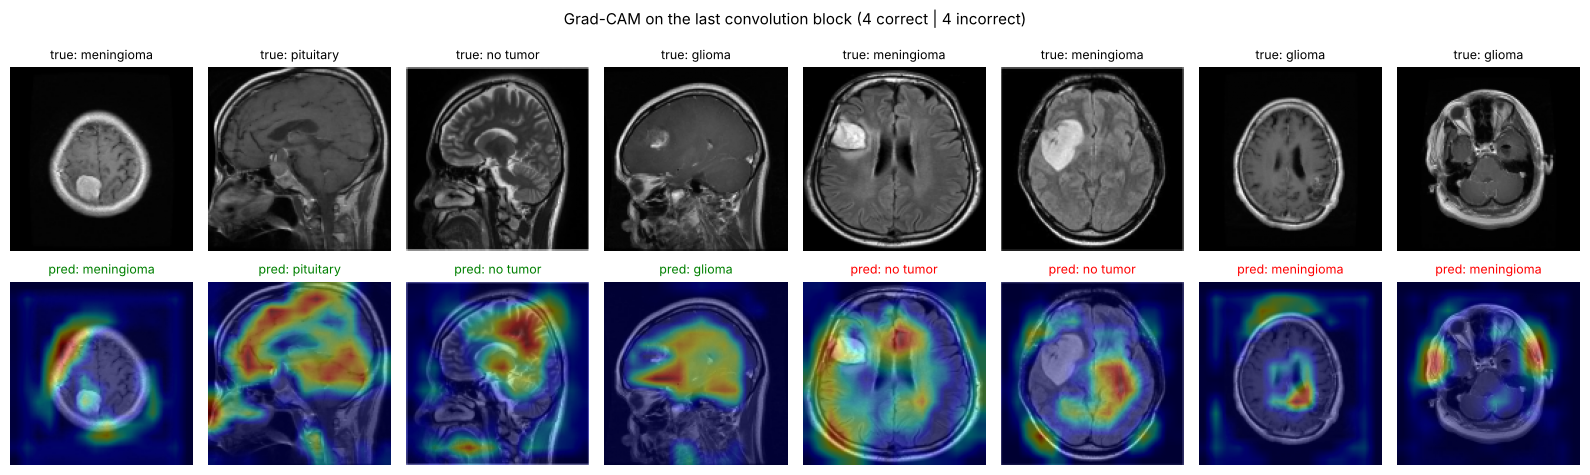

In [20]:
# Grad-CAM: which image regions increased the score of the predicted class (last conv block, relu4)
def grad_cam(model, x, layer="relu4"):
    store = {}
    h = dict(model.features.named_children())[layer].register_forward_hook(lambda m, i, o: store.__setitem__("a", o))
    model.eval(); out = model(x.to(DEVICE)); h.remove()
    cls = int(out.argmax(1)); g = torch.autograd.grad(out[0, cls], store["a"])[0]
    cam = F.relu((g.mean(dim=(2, 3), keepdim=True) * store["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0].detach().cpu().numpy()
    return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8), cls

sel = list(show[0][1][:4]) + list(show[1][1][:4])
fig, axes = plt.subplots(2, 8, figsize=(16, 5.0))
for c, j in enumerate(sel):
    i = test_ids[j]; cam, cls = grad_cam(main["model"], to_input(i))
    axes[0, c].imshow(X_basic[i], cmap="gray"); axes[0, c].set_title(f"true: {NAMES[y_test[j]]}", fontsize=9)
    axes[1, c].imshow(X_basic[i], cmap="gray"); axes[1, c].imshow(cam, cmap="jet", alpha=0.4)
    axes[1, c].set_title(f"pred: {NAMES[cls]}", fontsize=9, color="green" if cls == y_test[j] else "red")
for a in axes.ravel(): a.axis("off")
fig.suptitle("Grad-CAM on the last convolution block (4 correct | 4 incorrect)", fontsize=11)
plt.tight_layout(); savefig("06_gradcam"); plt.show()

**Observation (Task 6)**
* Test accuracy **0.873** (397 of 455 correct; 95 % CI 0.839–0.900), macro precision 0.862, macro recall 0.874, **macro F1 0.867**. The test loss (0.364) is somewhat higher than the best validation loss (0.280), as expected, because the validation set was used to pick the epoch.
* **Pituitary** is the easiest class (recall 0.992, F1 0.955): these tumors grow at one typical location (the sella turcica at the skull base) and look alike.
* The largest confusion is **glioma → meningioma** (20 of 136 gliomas). Both are intracranial masses that can look similar on a single 2-D slice. Meningioma errors are spread evenly over the other three classes (8 each).
* *No tumor* has the lowest precision (0.793): 12 tumor images (4 gliomas, 8 meningiomas) were called *no tumor*. Clinically these **false negatives** are the most serious error type.
* Wrong predictions are less confident (mean softmax 0.706 vs 0.915 for correct ones), so a low confidence is a useful warning sign, but some errors are made with 95–98 % confidence.
* Some errors are understandable from §1: two large meningiomas on FLAIR-like images (a contrast that is common in the *no tumor* class) were called *no tumor*, which fits the shortcut concern. One image labelled *no tumor* looks like a CT slice with a visible lesion, so its label itself is questionable.
* Grad-CAM shows that the model often uses large brain regions or even the skull edge rather than only the lesion, so its decisions would need much more validation before any clinical use.

## 7 · With vs. without image preprocessing, and two CNN configurations (Task 7)
A 2 × 2 experiment. Everything except the factor being compared is **identical**: same split, same seed, same optimizer, learning rate, batch size, epochs, early-stopping rule.

| | **CNN-A** (plain, 3 blocks) | **CNN-B** (4 blocks + BN + Dropout) |
|---|---|---|
| **Basic** (resize + tensor) | run 1 | run 2 |
| **Enhanced** (+ median, CLAHE, normalization, augmentation) | run 3 | run 4 = main model of §5 |

Runs 1–3 are trained below (run 4 is reused from §5).

In [21]:
for pipeline, config in [("Basic", "CNN-A"), ("Basic", "CNN-B"), ("Enhanced", "CNN-A")]:
    RUNS[(pipeline, config)] = train_model(config, pipeline, verbose=True)
    print(f"time: {RUNS[(pipeline, config)]['time']:.0f} s\n")

--- CNN-A + Basic preprocessing (1,072,196 parameters) ---


epoch  1 | train loss 1.1359 acc 0.493 | val loss 0.9265 acc 0.604 | lr 1.0e-03 |    8s  <- best


epoch  2 | train loss 0.8200 acc 0.659 | val loss 0.7438 acc 0.707 | lr 1.0e-03 |   16s  <- best


epoch  3 | train loss 0.6807 acc 0.728 | val loss 0.6032 acc 0.771 | lr 1.0e-03 |   24s  <- best


epoch  4 | train loss 0.5677 acc 0.781 | val loss 0.5561 acc 0.775 | lr 1.0e-03 |   31s  <- best


epoch  5 | train loss 0.4893 acc 0.816 | val loss 0.5177 acc 0.797 | lr 1.0e-03 |   39s  <- best


... (79 outputs left out)

epoch 31 | train loss 0.1219 acc 0.954 | val loss 0.3775 acc 0.901 | lr 2.5e-04 |  270s


epoch 32 | train loss 0.1198 acc 0.958 | val loss 0.3766 acc 0.899 | lr 2.5e-04 |  280s


epoch 33 | train loss 0.1092 acc 0.958 | val loss 0.3728 acc 0.896 | lr 2.5e-04 |  290s


epoch 34 | train loss 0.1074 acc 0.959 | val loss 0.3576 acc 0.899 | lr 2.5e-04 |  299s
early stopping after epoch 34; restoring best epoch 26
time: 299 s



In [22]:
ORDER = [("Basic", "CNN-A"), ("Basic", "CNN-B"), ("Enhanced", "CNN-A"), ("Enhanced", "CNN-B")]
rows, PRED = [], {}
for key in ORDER:
    run = RUNS[key]; r = {"preprocessing": key[0], "model": key[1], "params": count_params(run["model"]),
                          "best epoch": run["best_epoch"], "epochs run": run["epochs_run"]}
    for s in ["train_eval", "val", "test"]:
        pr, yt, loss = predict(run["model"], run["loaders"][s]); yp = pr.argmax(1)
        tag = "train" if s == "train_eval" else s
        r[f"{tag} loss"] = loss; r[f"{tag} acc"] = accuracy_score(yt, yp)
        if s == "test":
            p_, r_, f_, _ = precision_recall_fscore_support(yt, yp, average="macro", zero_division=0)
            r.update({"test precision": p_, "test recall": r_, "test F1": f_})
            lo, hi = wilson_ci((yp == yt).sum(), len(yt)); r["test acc 95% CI"] = f"{lo:.3f}-{hi:.3f}"
            PRED[key] = (yt, yp)
    r["train-val gap"] = r["train acc"] - r["val acc"]; r["time (s)"] = run["time"]
    rows.append(r)
results = pd.DataFrame(rows)
results.to_csv("results_comparison.csv", index=False)
for k, run in RUNS.items():
    json.dump(run["history"], open(f"history_{k[0]}_{k[1]}.json", "w"))

print("Table 1. Accuracy (train = best weights evaluated on the training images without augmentation)")
display(results[["preprocessing", "model", "params", "best epoch", "epochs run", "train acc", "val acc", "test acc",
                 "test acc 95% CI", "train-val gap", "time (s)"]].round(3))
print("Table 2. Loss and test-set macro metrics")
display(results[["preprocessing", "model", "train loss", "val loss", "test loss", "test precision", "test recall", "test F1"]].round(4))

Table 1. Accuracy (train = best weights evaluated on the training images without augmentation)


,preprocessing,model,params,best epoch,epochs run,train acc,val acc,test acc,test acc 95% CI,train-val gap,time (s)
0,Basic,CNN-A,1072196,12,20,0.996,0.890,0.851,0.815-0.880,0.106,166.500
1,Basic,CNN-B,1146612,26,34,0.977,0.936,0.879,0.846-0.906,0.041,414.649
2,Enhanced,CNN-A,1072196,26,34,0.983,0.888,0.888,0.856-0.914,0.096,299.158
3,Enhanced,CNN-B,1146612,60,60,0.957,0.896,0.873,0.839-0.900,0.060,766.872


Table 2. Loss and test-set macro metrics


,preprocessing,model,train loss,val loss,test loss,test precision,test recall,test F1
0,Basic,CNN-A,0.0350,0.3895,0.6108,0.8365,0.8555,0.8442
1,Basic,CNN-B,0.0602,0.2470,0.4521,0.8689,0.8676,0.8673
2,Enhanced,CNN-A,0.0588,0.3469,0.4207,0.8888,0.8895,0.8884
3,Enhanced,CNN-B,0.1545,0.2801,0.3641,0.8623,0.8741,0.8667


In [23]:
# Effect of each factor (difference in test accuracy / macro-F1, percentage points)
eff = []
for m in ["CNN-A", "CNN-B"]:
    a, b = results.set_index(["preprocessing", "model"]).loc[("Basic", m)], results.set_index(["preprocessing", "model"]).loc[("Enhanced", m)]
    eff.append(dict(comparison=f"Enhanced − Basic  ({m})", **{c: 100 * (b[c] - a[c]) for c in ["val acc", "test acc", "test F1"]}))
for p in ["Basic", "Enhanced"]:
    a, b = results.set_index(["preprocessing", "model"]).loc[(p, "CNN-A")], results.set_index(["preprocessing", "model"]).loc[(p, "CNN-B")]
    eff.append(dict(comparison=f"CNN-B − CNN-A  ({p})", **{c: 100 * (b[c] - a[c]) for c in ["val acc", "test acc", "test F1"]}))
print("Table 3. Effect of preprocessing and of the CNN configuration (percentage points)")
display(pd.DataFrame(eff).round(2))

Table 3. Effect of preprocessing and of the CNN configuration (percentage points)


,comparison,val acc,test acc,test F1
0,Enhanced − Basic (CNN-A),-0.22,3.74,4.42
1,Enhanced − Basic (CNN-B),-3.96,-0.66,-0.06
2,CNN-B − CNN-A (Basic),4.63,2.86,2.31
3,CNN-B − CNN-A (Enhanced),0.88,-1.54,-2.17


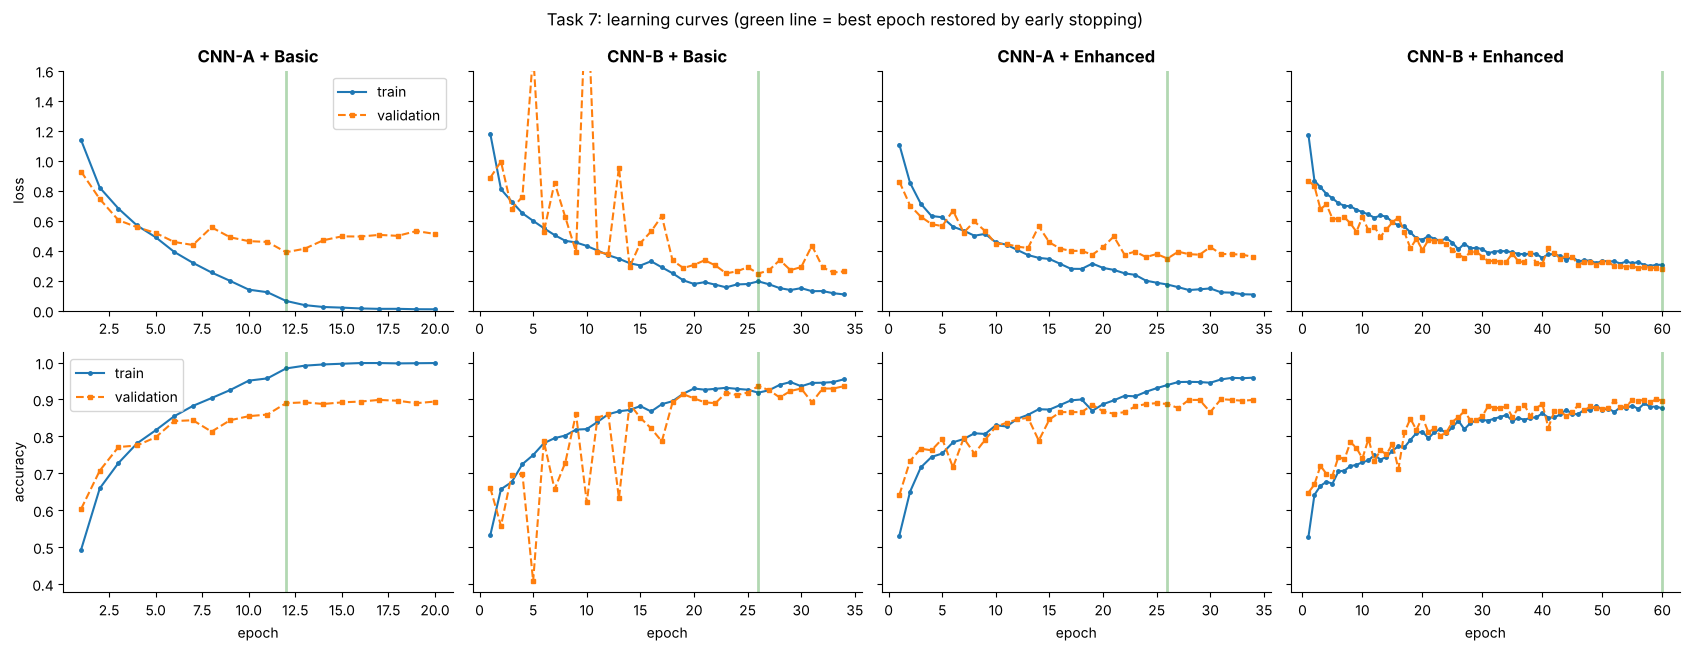

In [24]:
# Figure: learning curves of all four runs
fig, axes = plt.subplots(2, 4, figsize=(17, 6.6), sharey="row")
for c, key in enumerate(ORDER):
    h = RUNS[key]["history"]; ep = np.arange(1, len(h["train_loss"]) + 1); b = RUNS[key]["best_epoch"]
    axes[0, c].plot(ep, h["train_loss"], "o-", ms=2.5, label="train"); axes[0, c].plot(ep, h["val_loss"], "s--", ms=2.5, label="validation")
    axes[1, c].plot(ep, h["train_acc"], "o-", ms=2.5, label="train"); axes[1, c].plot(ep, h["val_acc"], "s--", ms=2.5, label="validation")
    axes[0, c].set_title(f"{key[1]} + {key[0]}", fontweight="bold")
    for r in range(2): axes[r, c].axvline(b, color="green", alpha=.3, lw=2)
    axes[1, c].set_xlabel("epoch")
axes[0, 0].set_ylabel("loss"); axes[1, 0].set_ylabel("accuracy"); axes[0, 0].legend(); axes[1, 0].legend()
axes[0, 0].set_ylim(0, 1.6)
fig.suptitle("Task 7: learning curves (green line = best epoch restored by early stopping)", fontsize=12)
plt.tight_layout(); savefig("07_learning_curves_all"); plt.show()

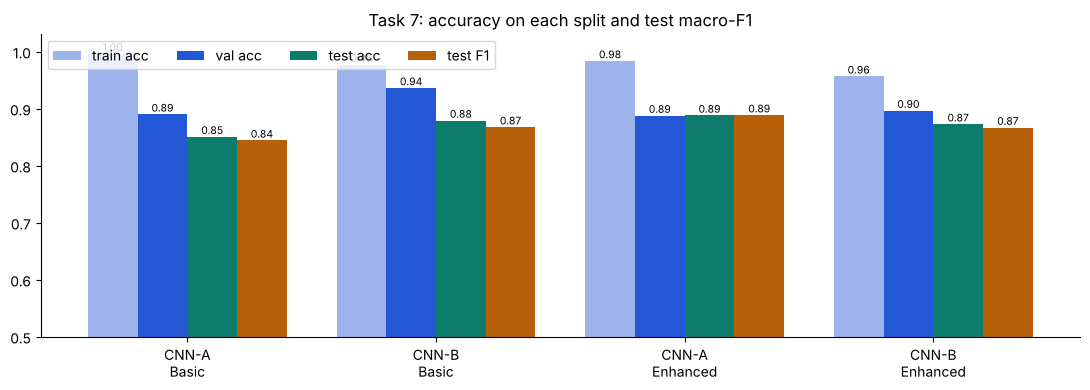

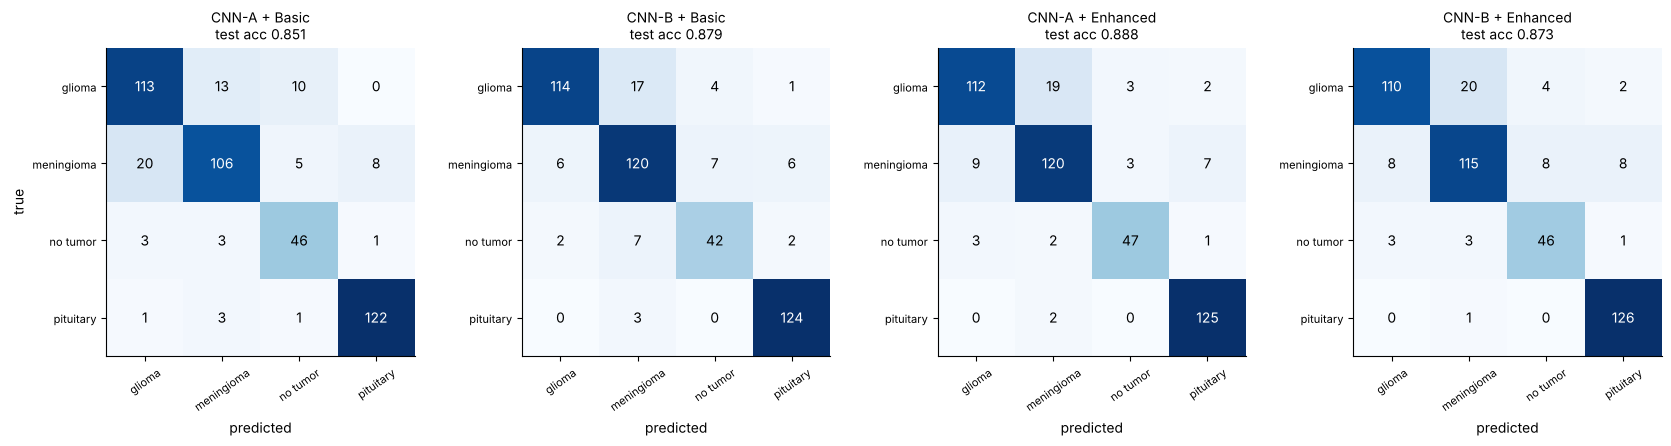

Table 4. Test recall (sensitivity) per class


,CNN-A + Basic,CNN-B + Basic,CNN-A + Enhanced,CNN-B + Enhanced
glioma,0.831,0.838,0.824,0.809
meningioma,0.763,0.863,0.863,0.827
no tumor,0.868,0.792,0.887,0.868
pituitary,0.961,0.976,0.984,0.992


In [25]:
# Figure: train / validation / test accuracy and test macro-F1 for each run
labels = [f"{m}\n{p}" for p, m in ORDER]
x = np.arange(4); wd = 0.2
fig, ax = plt.subplots(figsize=(11, 4))
for k, (col, c) in enumerate(zip(["train acc", "val acc", "test acc", "test F1"], ["#9DB4EB", "#2457D6", "#0E7C6B", "#B7600A"])):
    v = results[col].values; ax.bar(x + (k - 1.5) * wd, v, wd, label=col, color=c)
    for xi, vi in zip(x, v): ax.text(xi + (k - 1.5) * wd, vi + 0.005, f"{vi:.2f}", ha="center", fontsize=7.5)
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylim(0.5, 1.03); ax.legend(ncol=4, loc="upper left")
ax.set_title("Task 7: accuracy on each split and test macro-F1"); plt.tight_layout(); savefig("07_bar_metrics"); plt.show()

# Figure: test confusion matrices of the four runs
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
for a, key in zip(axes, ORDER):
    yt, yp = PRED[key]; M = confusion_matrix(yt, yp)
    a.imshow(M, cmap="Blues"); a.set_title(f"{key[1]} + {key[0]}\ntest acc {accuracy_score(yt, yp):.3f}", fontsize=10)
    a.set_xticks(range(4)); a.set_xticklabels(NAMES, rotation=35, fontsize=8); a.set_yticks(range(4)); a.set_yticklabels(NAMES, fontsize=8)
    for i in range(4):
        for j in range(4): a.text(j, i, M[i, j], ha="center", va="center", color="white" if M[i, j] > M.max() / 2 else "black")
axes[0].set_ylabel("true"); [a.set_xlabel("predicted") for a in axes]
plt.tight_layout(); savefig("07_confusion_all"); plt.show()

# Per-class recall (sensitivity) of every run
rec = pd.DataFrame({f"{m} + {p}": precision_recall_fscore_support(*PRED[(p, m)], zero_division=0)[1] for p, m in ORDER}, index=NAMES)
print("Table 4. Test recall (sensitivity) per class"); display(rec.round(3))

**Observation (Task 7)**
1. **The plain baseline overfits.** CNN-A + Basic memorises the training set (training accuracy 0.996, training loss 0.035); its validation loss is lowest at epoch 12 and then rises (0.511 at epoch 20). It has the largest train–validation gap (10.6 points), the lowest test accuracy (0.851) and by far the highest test loss (0.611), i.e. confident mistakes.
2. **Additional preprocessing helps the plain CNN.** With the Enhanced pipeline, CNN-A gains **+3.7 points test accuracy** (0.851 → 0.888) and +4.4 points macro-F1, and its test loss drops from 0.611 to 0.421. Augmentation delays memorisation (best epoch 26 instead of 12).
3. **BN + dropout also help.** With Basic preprocessing, CNN-B beats CNN-A by **+2.9 test points** (0.879 vs 0.851) with a much smaller gap (4.1 vs 10.6 points). Its early validation curve is very unstable (validation loss up to 2.23 at epoch 10), which is common while BN running statistics are still changing under a high learning rate; it settles after the learning-rate reductions.
4. **Combining both does not add up.** CNN-B + Enhanced (main model) reaches 0.873, slightly *below* the two single-regularisation runs (0.879 and 0.888, a difference within the noise, see point 5), but has the **lowest test loss (0.364)**, i.e. the best-calibrated probabilities. It learns slowest (needs all 60 epochs): augmentation, dropout, BN and weight decay together make the training task harder to fit in a fixed budget.
5. **Statistical caution.** All test accuracies lie between 0.851 and 0.888, their 95 % intervals overlap (about ±3 points with 455 test images), and every setting was run once. The clear result is the gap between the overfitting baseline and the three regularised runs (test loss 0.611 vs 0.36–0.45); the ranking among the three regularised runs is not reliable. Validation accuracies are optimistic because the validation set chose the epoch (e.g. CNN-B + Basic: 0.936 validation vs 0.879 test).
6. **Per class:** pituitary recall is ≥ 0.96 in every run, whereas glioma recall stays at 0.81–0.84 in every run: the glioma/meningioma confusion is solved neither by preprocessing nor by the architecture change.

## 8 · Explanations (Task 8)
### 8.1 Purpose of each CNN layer
| Layer (PyTorch) | Purpose |
|---|---|
| **Conv2d** 3×3, padding 1 | Slides learnable 3×3 filters over the input. Each filter produces one *feature map* that is large where its pattern (edge, texture, shape) appears. Padding 1 keeps the height and width unchanged. Weights are shared over all positions, so far fewer parameters than a fully connected layer. |
| **BatchNorm2d** (CNN-B) | Normalizes every channel over the mini-batch to mean 0 and variance 1, then rescales with learnable γ and β. Makes training faster and more stable and acts as a mild regularizer. |
| **ReLU** | Non-linearity f(z) = max(0, z). Without it, stacked layers would collapse into one linear map. Sets negative responses to 0 (sparse activations) and keeps gradients alive for positive inputs. |
| **MaxPool2d** 2×2, stride 2 | Keeps the largest value in every 2×2 window: halves height and width, reduces computation, gives a small tolerance to shifts, and lets deeper filters see a larger part of the image (larger *receptive field*). No parameters. |
| **Flatten** | Reshapes the C × H × W feature maps into one vector so fully connected layers can use it. No parameters. |
| **Dropout** p = 0.4 (CNN-B) | During training sets a random 40 % of the units to 0 (and scales the rest by 1/(1−p)), so the network cannot rely on single units; reduces overfitting. Disabled in evaluation. |
| **Linear (FC)** `fc1` | Combines all spatial features into 64 or 128 higher-level features. |
| **Linear (FC)** `fc2` | Produces one score (*logit*) per class (4 outputs). |
| **Softmax** (in the loss / at prediction) | Turns the 4 logits into probabilities that sum to 1. |

### 8.2 Symbols and equations
**Convolution** (PyTorch computes cross-correlation) for output channel $k$ at position $(i, j)$:
$$Y_k(i,j) = b_k + \sum_{c=1}^{C_{in}} \sum_{u=0}^{F-1}\sum_{v=0}^{F-1} W_{k,c}(u,v)\; X_c(S\,i+u-P,\; S\,j+v-P)$$

**Output size** of a convolution or pooling layer: $\;O = \left\lfloor \dfrac{N + 2P - F}{S} \right\rfloor + 1$. Example: conv 3×3, $P=1$, $S=1$: $O = N$. Max-pool 2×2, $S=2$: $O = N/2$ (128 → 64 → 32 → 16 → 8).

**Parameters:** convolution $(F\cdot F\cdot C_{in} + 1)\, C_{out}$ (without the $+1$ when `bias=False`); fully connected $n_{in}\, n_{out} + n_{out}$; batch norm $2C$ (γ, β).

| Operation | Equation |
|---|---|
| ReLU | $f(z) = \max(0, z)$ |
| Max pooling 2×2 | $Y(i,j) = \max_{u,v\in\{0,1\}} X(2i+u,\;2j+v)$ |
| Batch normalization | $\hat{x} = \dfrac{x-\mu_B}{\sqrt{\sigma_B^2+\epsilon}}, \quad y = \gamma\,\hat{x} + \beta$ |
| Dropout (training) | $\tilde{h}_i = \dfrac{m_i\, h_i}{1-p}, \quad m_i \sim \text{Bernoulli}(1-p)$ |
| Fully connected | $\mathbf{z} = W\mathbf{h} + \mathbf{b}$ |
| Softmax | $\hat{y}_k = \dfrac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}}$ |
| Cross-entropy loss | $\mathcal{L} = -\dfrac{1}{B}\sum_{n=1}^{B} \log \hat{y}_{n,\,t_n}$ |
| Adam update | $m_t=\beta_1 m_{t-1}+(1-\beta_1)g_t,\;\; v_t=\beta_2 v_{t-1}+(1-\beta_2)g_t^2,\;\; \theta_t=\theta_{t-1}-\eta\,\dfrac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}$, with $g_t = \nabla_\theta\mathcal{L} + \lambda\theta$ |
| Min-max scaling (both pipelines) | $x_{01} = x / 255$ |
| z-score normalization (Enhanced) | $x' = (x_{01} - \mu)/\sigma$, with $\mu, \sigma$ from the training images |
| Median filter 3×3 | output pixel = median of its 3×3 neighbourhood (removes salt-and-pepper / speckle noise, keeps edges) |
| CLAHE | histogram equalization in 8×8 tiles, histogram clipped at clip limit 2.0 first (limits noise amplification), tiles blended by bilinear interpolation |
| Accuracy | $\dfrac{\text{number of correct predictions}}{\text{number of images}}$ |
| Precision (class $k$) | $P_k = \dfrac{TP_k}{TP_k+FP_k}$ |
| Recall / sensitivity (class $k$) | $R_k = \dfrac{TP_k}{TP_k+FN_k}$ |
| F1-score (class $k$) | $F1_k = \dfrac{2\,P_k R_k}{P_k + R_k}$ |
| Macro average | $\dfrac{1}{K}\sum_{k=1}^{K} M_k$ for $M \in \{P, R, F1\}$ |

| Symbol | Meaning | Symbol | Meaning |
|---|---|---|---|
| $X, Y$ | input / output feature map | $W, b$ | weights, bias |
| $N$ | input height (= width) | $F$ | filter (kernel) size, here 3 |
| $P$ | padding | $S$ | stride |
| $C_{in}, C_{out}$ | input / output channels | $K$ | number of classes (4) |
| $B$ | batch size (32) | $t_n$ | true class of image $n$ |
| $z_k$ | logit of class $k$ | $\hat{y}_k$ | predicted probability of class $k$ |
| $\mu_B, \sigma_B^2$ | batch mean / variance | $\gamma, \beta$ | BN scale and shift |
| $\epsilon$ | small constant for numerical stability | $p$ | dropout probability (0.4) |
| $\eta$ | learning rate (1e-3) | $\lambda$ | weight decay (1e-4) |
| $\beta_1, \beta_2$ | Adam moment decay rates (0.9, 0.999) | $m_t, v_t$ | Adam first / second moment estimates |
| $\mu, \sigma$ | training-set pixel mean / std | $TP, FP, FN, TN$ | true / false positives / negatives |

### 8.3 Abbreviations
| Abbreviation | Meaning | Abbreviation | Meaning |
|---|---|---|---|
| CNN | Convolutional Neural Network | MRI | Magnetic Resonance Imaging |
| Conv | convolution layer | ReLU | Rectified Linear Unit |
| BN | Batch Normalization | FC | Fully Connected (linear) layer |
| CLAHE | Contrast Limited Adaptive Histogram Equalization | CE | Cross-Entropy |
| Adam | Adaptive Moment Estimation (optimizer) | LR | Learning Rate |
| TP / FP / FN / TN | true positive / false positive / false negative / true negative | CI | Confidence Interval |
| Grad-CAM | Gradient-weighted Class Activation Mapping | CPU / GPU | Central / Graphics Processing Unit |

### 8.4 Overall conclusions and limitations
* A small CNN (≈ 1.1 M parameters) trained from scratch on 2,118 MRI slices separates the four classes with **85–89 % test accuracy**; the main model reaches 0.873 accuracy and 0.867 macro-F1.
* The plain network overfits. Regularisation through **additional preprocessing (CLAHE, denoising, normalization, augmentation)** or through **BN + dropout** each raised test accuracy by about 3–4 points and clearly reduced over-confident errors (test loss). Combining both did not raise accuracy further within our budget but gave the lowest test loss.
* Hardest distinction: glioma vs. meningioma. Easiest class: pituitary. The most serious errors are tumors predicted as *no tumor*.
* **Limitations:** one run per setting (no repeated seeds or cross-validation); a small public dataset with source differences between the classes (shortcut risk) and some questionable labels; 2-D slices of mixed views without patient IDs (slices of one patient may fall into different splits); CPU budget (128×128 pixels, at most 60 epochs). This model is a course exercise, not a diagnostic tool.
* **Next steps:** repeat every setting with 3–5 seeds or 5-fold cross-validation; transfer learning from a pretrained network (e.g. ResNet-18); a class-weighted loss for the *no tumor* class; testing on images from another hospital.

### References
* S. Bhuvaji, A. Kadam, P. Bhumkar, S. Dedge, S. Kanchan, *Brain Tumor Classification (MRI)*, 2020. GitHub: sartajbhuvaji/brain-tumor-classification-dataset; Kaggle: sartajbhuvaji/brain-tumor-classification-mri.
* PyTorch documentation (pytorch.org/docs): `nn.Conv2d`, `nn.BatchNorm2d`, `nn.MaxPool2d`, `nn.CrossEntropyLoss`, `optim.Adam`.
* K. Zuiderveld, "Contrast Limited Adaptive Histogram Equalization", *Graphics Gems IV*, 1994.
* S. Ioffe, C. Szegedy, "Batch Normalization", ICML 2015. N. Srivastava *et al.*, "Dropout", JMLR 2014. D. Kingma, J. Ba, "Adam", ICLR 2015.
* R. Selvaraju *et al.*, "Grad-CAM", ICCV 2017.
* Course notebook: *CNN Lab: Train, Validate, Test* (M5261).